# Cât `edge` îi trebuie unui model secundar? Etichete noi și primare sintetice

**`btcusdt_v2`** · Binance USDⓈ-M BTCUSDT perpetual · continuarea notebook-ului `btcusdt_v2_metalabeling_multistrategy.ipynb` · `EXPLORATORY`

## Rezumat

**Întrebarea.** Notebook-ul anterior a arătat că modelul secundar prezice volatilitatea, nu direcția, și că nu poate fi măsurat cum depinde de `edge`, fiindcă regulile reale nu au. Aici: (A) schimbă eticheta ceva pe regulile reale? (B) pe primare sintetice cu `edge` reglabil, când și cât ajută un model secundar?

**Răspunsul scurt.** Modelul secundar ajută doar dacă există `edge` **și** acel `edge` variază cu ceva observabil la decizie. Mărimea `edge`-ului singură nu ajunge: la același `edge` mediu, valoarea filtrului e de la aproape zero la +18 bps pe eveniment, după cum e distribuit `edge`-ul. Pe regulile reale nicio etichetă nu creează valoare.

| Întrebare | Răspuns | Dovada |
|---|---|---|
| Eticheta nouă ajută regulile reale? | Nu | Uplift mediu între −0.1 și +0.6 bps, toate intervalele includ zero. Nicio etichetă nu bate `NET` |
| Fără `edge`, ajută un filtru? | Nu | La `q = 0.5`, uplift în jur de zero pe toate tipurile și frecvențele |
| `Edge` constant în rata de acuratețe (`HIT`) | Puțin, și doar cu eticheta în bps | La 22 bps de `edge`, filtrul `GB` adaugă +5.9 bps, `DIR` nimic. Volatilitatea devine bani doar când există `edge` |
| `Edge` constant în bps (`BPS`) | Practic nimic | Uplift sub 2.3 bps la orice `edge`, deși AUC-ul pe direcție urcă la 0.62 |
| `Edge` concentrat într-un regim (`REGIME`) | Mult | Uplift +3 la +4.5 bps la 9 bps de `edge`, +18 bps la 27 bps |
| Rolul lui N | Contează când există ce învăța | La 9 bps `edge` în regim: +1.8 bps la 165 de evenimente efective, +4.3 la 960. Zgomotul între replici scade de 2–3 ori |
| AUC și log loss ca ghid | Înșelătoare | `BPS`: AUC 0.62 cu uplift aproape zero. `HIT`: AUC 0.53 cu uplift +5.9 |
| Bare | Fără diferențe | Același tipar pe `time_1m`, `volume_adapt60s`, `cusum_adapt_c1` |
| Cât `edge` trebuie? | Aproape tot costul | Fără filtru, netul devine pozitiv de la 10 bps brut. Cu filtru: de la ~9 bps (`HIT`) și ~7 bps (`REGIME`) |

**Ce înseamnă pentru notebook-ul anterior.** Răspunsul la "funcționează modelul secundar diferit în funcție de `edge`?" este da, dar nu monoton cu mărimea lui. Contează dacă `edge`-ul are o structură pe care features o pot vedea. De aceea regulile reale, fără `edge`, nu aveau ce oferi modelului.

**Cum se citește.** Secțiunea 2 e designul, cu predicțiile scrise înainte de rulare. Partea A e în secțiunea 5, Partea B în secțiunea 6, concluziile în secțiunea 7.

## 1. Setup

Mediu `disertatie`. Citește doar `derived/datasets/btcusdt_v2` și `derived/canonical/trades`. Codul de execuție, etichetare și features e același ca în notebook-ul anterior, ca rezultatele să fie comparabile. `META_DRY_RUN=1` mută testul pe luni de dezvoltare și reduce grila.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMBA_NUM_THREADS"):
    os.environ[_v] = "1"          # one thread per process: parallelism comes from the process pool only
import hashlib, json, multiprocessing as mp, pickle, platform, resource, sys, time, warnings
from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
import lightgbm as lgb
import numba
import scipy
import sklearn
import statsmodels
import statsmodels.api as sm
from numba import njit
from scipy import stats
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform
from scipy.special import expit, logit
from sklearn.linear_model import LogisticRegression
from statsmodels.stats.multitest import multipletests

T0 = time.time()
SEED = 20261107
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

def find_repo_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data/cryptohftdata/derived/datasets/btcusdt_v2/manifest.json").exists():
            return p
    raise FileNotFoundError("Run this notebook from inside the QuantForge repository.")

ROOT = find_repo_root()
CHDDS = ROOT / "data/cryptohftdata"
DATA = CHDDS / "derived/datasets/btcusdt_v2"
TRADES = CHDDS / "derived/canonical/trades"
sys.path.insert(0, str(CHDDS))
from chdds.dataset import incident_rows

man = json.loads((DATA / "manifest.json").read_text())
DRY_RUN = os.environ.get("META_DRY_RUN") == "1"
CACHE = os.environ.get("META_CACHE")
WORKERS = int(os.environ.get("META_WORKERS", "12"))

def source_fingerprint():
    files = sorted(DATA.rglob("*.parquet")) + [DATA / "manifest.json"] + sorted(TRADES.glob("*.parquet"))
    return (len(files), sum(f.stat().st_size for f in files), max(f.stat().st_mtime_ns for f in files))
FINGERPRINT_START = source_fingerprint()

def cached(name, fn):
    # Optional stage cache. Without META_CACHE every stage is recomputed.
    if CACHE:
        p = Path(CACHE) / f"{name}{'_dry' if DRY_RUN else ''}.pkl"
        if p.exists():
            return pickle.loads(p.read_bytes())
    out = fn()
    if CACHE:
        Path(CACHE).mkdir(parents=True, exist_ok=True)
        p.write_bytes(pickle.dumps(out, protocol=5))
    return out

def pmap(fn, items, workers=None, key=None):
    # Fork pool: workers inherit the read-only globals, so no data is pickled in. Results keep input order.
    # ProcessPoolExecutor raises BrokenProcessPool on a worker crash, where multiprocessing.Pool would hang.
    items = list(items)
    order = sorted(range(len(items)), key=(lambda i: -key(items[i])) if key else (lambda i: i))
    out = [None] * len(items)
    with ProcessPoolExecutor(workers or WORKERS, mp_context=mp.get_context("fork")) as ex:
        futs = {ex.submit(fn, items[i]): i for i in order}
        for f in as_completed(futs):
            out[futs[f]] = f.result()
    return out

C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", red="#e34948", purple="#7a5bd0", gold="#c99a1e")
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("seq", ["#f0efec", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])     # red < 0 < blue
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10, "font.family": "sans-serif",
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "lines.linewidth": 1.8, "legend.frameon": False, "legend.fontsize": 9,
})
pd.set_option("display.width", 220, "display.max_columns", 60, "display.max_rows", 300, "display.max_colwidth", 90)
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | lightgbm {lgb.__version__} | scikit-learn {sklearn.__version__} | statsmodels {statsmodels.__version__}")
print(f"Dataset: {DATA.name} | created {man['created_utc']} | book mode {man['book_provenance']['book_mode']} | workers {WORKERS} | dry run {DRY_RUN}")

Python 3.11.13 | pandas 2.3.3 | numpy 2.0.2 | lightgbm 4.6.0 | scikit-learn 1.7.2 | statsmodels 0.14.5
Dataset: btcusdt_v2 | created 2026-11-05T20:01:10Z | book mode rebuilt | workers 14 | dry run False


## 2. Designul, fixat înainte de rezultate

Notebook-ul anterior a lăsat două probleme deschise:

1. **Eticheta `net > 0` recompensează volatilitatea, nu profitul.** Ar trebui verificat dacă alte etichete selectează mai bine.
2. **Efectul `edge`-ului nu a putut fi măsurat**, fiindcă nicio regulă reală nu are `edge` demonstrat.

### 2.1 Partea A: patru etichete pe regulile reale

Aceleași 17 reguli, 9 seturi de bare și 3 blocuri forward. Modelul e fix, fără căutare, fiindcă tuning-ul nu a ajutat în notebook-ul anterior.

| Etichetă | Tip | Ce învață |
|---|---|---|
| `NET` | Clasificare, `net > 0` | Referința din notebook-ul anterior |
| `DIR` | Clasificare, target înainte de stop, doar pe ieșirile la barieră | Direcția |
| `GW` | Regresie pe `gross / lățime` | Rezultatul în unități de barieră |
| `GB` | Regresie pe bps brut | Banii, inclusiv scala volatilității |

Fiecare etichetă păstrează jumătatea de sus a scorurilor. Pragul vine din scoruri out-of-fold (purged 3-fold) pe antrenament. `GB` are și o regulă de valoare așteptată: păstrează tranzacția dacă brutul prezis depășește costul.

### 2.2 Partea B: primare sintetice cu `edge` cunoscut

Am nevoie de o primară al cărei `edge` îl pot regla fără să schimb nimic altceva. Pornesc de la momente aleatoare și las un **oracol** să aleagă partea: cu probabilitatea `q` alege partea care a câștigat efectiv, altfel opusa.

Viitorul intră **doar în alegerea părții**. Features rămân cele reale, cunoscute la decizie, iar modelul secundar nu vede oracolul. Nu e o strategie, ci un instrument de măsură, ca semnalul injectat din notebook-ul anterior. La `q = 0.5` e o primară aleatoare.

**Trei tipuri de `edge`, cu același `edge` mediu.**

| Tip | Regula oracolului | Ce reprezintă |
|---|---|---|
| `HIT` | `q` constant | Predictor cu rată de acuratețe constantă. `Edge`-ul în bps crește cu volatilitatea |
| `BPS` | `q` scade cu lățimea barierei | `Edge` constant în bps, indiferent de volatilitate |
| `REGIME` | `q` ridicat când un feature real e peste mediană, 0.5 altfel | `Edge` concentrat într-un regim, adică exact cazul pentru care există meta-labeling |

Pentru `REGIME`, feature-ul se alege la întâmplare în fiecare replică din cinci coloane nedirecționale: `oi_chg_4h`, `l_fano_15m`, `rel_depth_10bps`, `sign_acf_1`, `large_share_15m`. Rezultatul nu depinde astfel de o coloană anume, iar coloana e ascunsă printre cele 99.

**Grila.** `q` mediu ∈ {0.50, 0.54, 0.58, 0.62, 0.66, 0.70} × 3 frecvențe (1, 3, 9 evenimente pe zi) × 3 tipuri × 16 replici pe `time_1m`. Pe `volume_adapt60s` și `cusum_adapt_c1`: frecvența 3, 8 replici. Orizont 4 h, aceleași bariere, costuri și blocuri. Frecvența schimbă N-ul, `q` schimbă `edge`-ul, iar cele două se variază **independent**: exact ce nu permiteau datele reale.

**Replicile împart aceeași piață**, deci variația dintre ele arată zgomotul oracolului și al eșantionării, nu incertitudinea despre piață.

### 2.3 Predicții, scrise înainte de rulare

| # | Predicție | Motivul |
|---|---|---|
| P1 | La `HIT`, uplift-ul crește cu `edge`-ul, chiar dacă modelul nu știe direcția | `Edge`-ul în bps e proporțional cu mișcarea, deci informația despre volatilitate devine bani |
| P2 | La `BPS`, uplift-ul rămâne aproape de zero | Mișcarea mai mare nu aduce `edge` mai mare |
| P3 | La `REGIME`, uplift-ul crește cu `edge`-ul și cu N, iar `DIR` bate `NET` | Doar aici există ceva de selectat prin direcție |
| P4 | AUC-ul pe `NET` nu indică valoarea: la `HIT` și `BPS` e cam același, deși valoarea filtrului diferă | AUC-ul vine din volatilitate |
| P5 | Pe regulile reale, nicio etichetă nu bate filtrul aleator | Regulile nu au `edge` |

**Criteriu pentru Partea A.** O etichetă e mai bună dacă uplift-ul mediu pe reguli are intervalul de 95% peste zero și peste al lui `NET`, iar proporția de celule peste percentila 95 a filtrului aleator depășește clar 5%.

**Criteriu pentru Partea B.** O predicție e confirmată dacă semnul și ordinea se văd la toate cele 3 frecvențe.

**Nivelul de evidență.** Partea A e `EXPLORATORY`, pe date deja folosite. Partea B măsoară proprietăți ale metodei, nu ale pieței, deci nu are nevoie de date nevăzute, dar concluzia e valabilă doar pentru tipurile de `edge` simulate.

### 2.4 Parametrii ficși

In [2]:
UTC = "UTC"
TRAIN_START = pd.Timestamp("2025-07-22", tz=UTC)      # first day of the 52 ms cadence regime
DATA_END = pd.Timestamp("2026-11-01", tz=UTC)
CRASH_START, CRASH_END = pd.Timestamp("2025-10-09", tz=UTC), pd.Timestamp("2025-10-12", tz=UTC)
SCAN_END = pd.Timestamp("2026-02-01", tz=UTC)         # primaries were chosen on outcomes before this date only

BLOCKS = [("2026-02-01", "2026-05-01"), ("2026-05-01", "2026-08-01"), ("2026-08-01", "2026-11-01")]
ALL_BARS = ["time_1m", "time_5m", "volume_50btc", "volume_adapt60s", "dollar_5musdt", "dollar_adapt60s", "cusum_5bps", "cusum_10bps", "cusum_adapt_c1"]
BAR_TYPE = {"time_1m": "Time", "time_5m": "Time", "volume_50btc": "Volume", "volume_adapt60s": "Volume", "dollar_5musdt": "Dollar", "dollar_adapt60s": "Dollar",
            "cusum_5bps": "CUSUM", "cusum_10bps": "CUSUM", "cusum_adapt_c1": "CUSUM"}
FACTORIAL_BARS = []
if DRY_RUN:
    BLOCKS = [("2025-11-15", "2025-12-15"), ("2025-12-15", "2026-02-01")]
    ALL_BARS = ["time_1m", "volume_adapt60s", "cusum_adapt_c1"]
BLOCKS = [(pd.Timestamp(a, tz=UTC), pd.Timestamp(b, tz=UTC)) for a, b in BLOCKS]
FIRST_TEST, TEST_END = BLOCKS[0][0], BLOCKS[-1][1]

# Execution, shared with the pilot.
K_BARRIER, LATENCY_S, MAX_WAIT_S, FEE_SIDE_BPS, FRESH_MS = 1.0, 1, 5, 5.0, 10_000
COST_RT_BPS = 2 * FEE_SIDE_BPS

# Validation.
K_FOLDS = 5
EMBARGO_NS = 24 * 3600 * 10**9       # longest feature window; also longer than every label
RETENTIONS = [0.3, 0.5, 0.7]
MAX_MISSING = 0.30
MIN_TRAIN = 80                       # below this a block is not modelled at all
SE_RULE = 1.0                        # one-standard-error rule for model choice

# Inference thresholds, fixed before results.
AUC_RELEVANT = 0.55                  # smallest AUC treated as useful
MIN_TEST_TRADES = 100
BOOT_REPS, BOOT_BLOCK_D = 1000, 5
RANDOM_FILTER_REPS = 300
N_PLACEBO = 2 if DRY_RUN else 20
N_INJECT = 1 if DRY_RUN else 5
N_MATCH_REPS = 2 if DRY_RUN else 6
MATCH_GRID = [100, 200, 400, 800, 1600]
INJECT_AUC = 0.60

# Hyperparameter search. Ordered from simplest to most flexible: the order is the complexity rank used by the one-SE rule.
LGB_BASE = dict(objective="binary", bagging_freq=1, max_bin=63, num_threads=1, deterministic=True, force_row_wise=True, verbosity=-1)
CONFIGS = ([dict(kind="logit", C=c) for c in (0.001, 0.003, 0.01, 0.03, 0.1)] +
           [dict(kind="lgb", rounds=r, learning_rate=lr, num_leaves=nl, max_depth=d, min_data_in_leaf=m, feature_fraction=ff, bagging_fraction=.7, lambda_l2=l2)
            for r, lr, nl, d, m, ff, l2 in [(60, .03, 3, 2, 60, .3, 50.), (60, .05, 3, 2, 40, .5, 20.), (100, .03, 4, 2, 40, .3, 20.), (100, .03, 4, 3, 30, .5, 50.),
                                            (150, .03, 6, 3, 30, .5, 20.), (100, .05, 6, 3, 20, .5, 20.), (200, .03, 6, 3, 40, .3, 50.), (200, .05, 8, 4, 20, .5, 5.)]])
FEATURE_SETS = ["CORE", "SEL", "ALL"]                  # also simplest first
LGB_REF = dict(rounds=120, learning_rate=.03, num_leaves=4, max_depth=2, min_data_in_leaf=30, feature_fraction=.4, bagging_fraction=.7, lambda_l2=30.)
LOGIT_REF_C = 0.01
print(f"Test blocks: {[f'{a.date()} to {b.date()}' for a, b in BLOCKS]} | bar sets {len(ALL_BARS)} | configs {len(CONFIGS)} x sets {len(FEATURE_SETS)} x retentions {len(RETENTIONS)} = {len(CONFIGS) * len(FEATURE_SETS) * len(RETENTIONS)} candidates per block")

Test blocks: ['2026-02-01 to 2026-05-01', '2026-05-01 to 2026-08-01', '2026-08-01 to 2026-11-01'] | bar sets 9 | configs 13 x sets 3 x retentions 3 = 117 candidates per block


## 3. Stratul comun: execuție, primare, etichete, features

Tape-ul de 1 secundă, scala de volatilitate, funding-ul și motorul de ieșire sunt preluate din pilot, cu o singură schimbare: orizontul devine parametru pe eveniment, fiindcă strategiile au orizonturi diferite. Testele motorului sunt păstrate, deci o eroare aici oprește notebook-ul.

In [3]:
SEC0 = int(pd.Timestamp("2025-06-28", tz=UTC).timestamp())
N_SEC = int(pd.Timestamp("2026-11-02", tz=UTC).timestamp()) - SEC0

@njit
def tape_add(sec, px, hi, lo, cl):
    # Prices are integer cents. A value of 0 means no trade in that second.
    for i in range(sec.size):
        s = sec[i]; p = px[i]
        if hi[s] == 0:
            hi[s] = p; lo[s] = p
        else:
            if p > hi[s]: hi[s] = p
            if p < lo[s]: lo[s] = p
        cl[s] = p

def build_tape():
    hi = np.zeros(N_SEC, np.int32); lo = np.zeros(N_SEC, np.int32); cl = np.zeros(N_SEC, np.int32)
    for f in sorted(TRADES.glob("*.parquet")):
        tb = pq.read_table(f, columns=["recv_ns", "price_e2"])
        tape_add(tb["recv_ns"].to_numpy() // 10**9 - SEC0, tb["price_e2"].to_numpy().astype(np.int32), hi, lo, cl)
    return hi, lo, cl

t_ = time.time()
HI, LO, CL = cached("tape", build_tape)
print(f"Tape ready in {time.time() - t_:.0f} s, {HI.nbytes * 3 / 1e9:.2f} GB. Seconds with a trade in the study window: "
      f"{np.mean(HI[int(TRAIN_START.timestamp()) - SEC0:int(DATA_END.timestamp()) - SEC0] > 0):.2%}.")

NO_FILL, EXIT_PT, EXIT_SL, EXIT_TIME = 0, 1, 2, 3

@njit
def resolve(entry0, side, width, horizon, hi, lo, max_wait):
    n = entry0.size; N = hi.size
    reason = np.zeros(n, np.int8)
    e_sec = np.full(n, -1, np.int64); x_sec = np.full(n, -1, np.int64)
    e_px = np.full(n, np.nan); x_px = np.full(n, np.nan)
    for i in range(n):
        w = width[i]
        if not (w > 0.0):
            continue
        e = -1
        for s in range(entry0[i], min(entry0[i] + max_wait + 1, N)):
            if hi[s] > 0:
                e = s
                break
        if e < 0:
            continue
        long_ = side[i] > 0
        ep = float(hi[e]) if long_ else float(lo[e])     # worst price in the fill second
        pt = ep * np.exp(w) if long_ else ep * np.exp(-w)
        sl = ep * np.exp(-w) if long_ else ep * np.exp(w)
        last = e + horizon[i]
        if last >= N:
            continue
        done = False
        for s in range(e + 1, last + 1):
            if hi[s] == 0:
                continue
            if long_:
                t_sl = lo[s] <= sl; t_pt = hi[s] > pt
            else:
                t_sl = hi[s] >= sl; t_pt = lo[s] < pt
            if t_sl:                                     # checked first: the stop wins any tie
                reason[i] = EXIT_SL; x_sec[i] = s
                x_px[i] = float(lo[s]) if long_ else float(hi[s])
                done = True
                break
            if t_pt:
                reason[i] = EXIT_PT; x_sec[i] = s; x_px[i] = pt
                done = True
                break
        if not done:
            s = last
            while s < N and hi[s] == 0:
                s += 1
            if s >= N:
                continue
            reason[i] = EXIT_TIME; x_sec[i] = s
            x_px[i] = float(lo[s]) if long_ else float(hi[s])
        e_sec[i] = e; e_px[i] = ep
    return reason, e_sec, e_px, x_sec, x_px

def one_trade(hi, lo, side, w=np.log(1.01) + 1e-12, horizon=20, wait=2):
    r, es, ep, xs, xp = resolve(np.array([1]), np.array([side]), np.array([w]), np.array([horizon]), hi, lo, wait)
    return dict(reason=int(r[0]), ep=ep[0], xp=xp[0], x_sec=int(xs[0]), gross=side * (xp[0] / ep[0] - 1) * 1e4 if r[0] else np.nan)

def path():
    return np.full(40, 10_000, np.int32), np.full(40, 10_000, np.int32)

h, l = path(); h[5] = 10_200
o = one_trade(h, l, +1); assert o["reason"] == EXIT_PT and abs(o["gross"] - 100) < 1e-6
h, l = path(); l[5] = 9_800
o = one_trade(h, l, +1); assert o["reason"] == EXIT_SL and o["xp"] == 9_800 and o["gross"] < -100
h, l = path(); h[5], l[5] = 10_200, 9_800
o = one_trade(h, l, +1); assert o["reason"] == EXIT_SL
h, l = path(); l[5] = 9_800
o = one_trade(h, l, -1); assert o["reason"] == EXIT_PT and o["gross"] > 0
h, l = path(); h[5] = 10_200
o = one_trade(h, l, -1); assert o["reason"] == EXIT_SL and o["gross"] < 0
h, l = path()
o = one_trade(h, l, +1); assert o["reason"] == EXIT_TIME and o["x_sec"] == 21
o = one_trade(h, l, +1, horizon=7); assert o["reason"] == EXIT_TIME and o["x_sec"] == 8      # horizon is per event
h, l = path(); h[5] = 10_100
o = one_trade(h, l, +1); assert o["reason"] == EXIT_TIME
h, l = path(); h[5:10] = 0; l[5:10] = 0; l[10] = 9_500
o = one_trade(h, l, +1); assert o["reason"] == EXIT_SL and o["xp"] == 9_500
h, l = path(); h[1:6] = 0; l[1:6] = 0
o = one_trade(h, l, +1); assert o["reason"] == NO_FILL
h, l = path(); h[1] = 10_050
o = one_trade(h, l, +1); assert o["ep"] == 10_050
print("All 11 exit-engine tests passed.")

Tape ready in 127 s, 0.51 GB. Seconds with a trade in the study window: 95.47%.


All 11 exit-engine tests passed.


In [4]:
LIGHT = '''decision_time_ns t_start_ns eval_time_ns complete feed_complete last_trade_age_ms book_state bar_close
ret_trade_15m ret_trade_1h ret_trade_4h ret_trade_24h bar_duration_s tfi_ratio_2m tfi_ratio_15m ofi_norm_2m qi_5bps log1p_liq_notional_15m liq_imbalance_15m
basis_mark_index_bps funding_rate_asof oi_log_change_known_4h notional_15m_usdt markout_30s_qw_bps_15m
cost_buy_1000000usdt_atmid_bps cost_sell_1000000usdt_atmid_bps'''.split()

def spec_id(name):
    return next(k for k, v in man["bar_sets"].items() if v["name"] == name)

def bar_files(name):
    return sorted((DATA / spec_id(name)).glob("*.parquet"))

def load_bars(name, columns):
    b = pd.concat([pq.read_table(f, columns=columns).to_pandas() for f in bar_files(name)], ignore_index=True)
    b.index = pd.DatetimeIndex(pd.to_datetime(b["decision_time_ns"], utc=True), name="t")
    return b

def safe_log(x):
    return np.log(x.where(x > 0))

def slog(x):
    return np.sign(x) * np.log1p(np.abs(x))

REL_SOURCES = {
    "notional_2m": lambda b: b["notional_2m_usdt"], "notional_15m": lambda b: b["notional_15m_usdt"], "trades_15m": lambda b: b["trade_count_15m"],
    "trade_size_2m": lambda b: b["mean_trade_size_2m_btc"], "depth_10bps": lambda b: b["depth_bid_10bps_btc"] + b["depth_ask_10bps_btc"],
    "tw_spread_2m": lambda b: b["tw_spread_bps_2m"], "cost_1m": lambda b: (b["cost_buy_1000000usdt_atmid_bps"] + b["cost_sell_1000000usdt_atmid_bps"]) / 2,
    "eff_spread_2m": lambda b: b["eff_spread_qw_bps_2m"], "level_changes_2m": lambda b: b["book_level_changes_2m"]}

COMMON_COLS = sorted(set(LIGHT) | {"notional_2m_usdt", "trade_count_15m", "mean_trade_size_2m_btc", "depth_bid_10bps_btc", "depth_ask_10bps_btc", "tw_spread_bps_2m",
                                   "eff_spread_qw_bps_2m", "book_level_changes_2m"})
TRAIL = 7 * 1440

def trend_scan(lc, windows=(30, 60, 120, 240)):
    # Largest |t| of an OLS slope on the last L minutes. Past data only, computed on the one-minute grid.
    y = np.nan_to_num(lc - np.nanmean(lc))
    out = []
    for n in windows:
        x = np.arange(n) - (n - 1) / 2; sxx = (x ** 2).sum()
        sxy = np.convolve(y, x[::-1], mode="full")[:y.size]
        s1 = pd.Series(y).rolling(n).sum().to_numpy(); s2 = pd.Series(y ** 2).rolling(n).sum().to_numpy()
        slope = sxy / sxx
        rss = np.maximum(s2 - s1 ** 2 / n - slope * sxy, 1e-14)
        out.append(np.nan_to_num(slope / np.sqrt(rss / (n - 2) / sxx)))
    T = np.stack(out)
    return T[np.argmax(np.abs(T), 0), np.arange(T.shape[1])]

def build_common():
    g = load_bars("time_1m", COMMON_COLS)
    px = g["bar_close"].where(g["last_trade_age_ms"] <= FRESH_MS)
    r2 = np.log(px).diff() ** 2
    Cm = {"t": g["decision_time_ns"].to_numpy(),
          "sig": np.sqrt(r2.rolling(240, min_periods=120).mean()).clip(lower=2e-5).to_numpy(),
          "sig24": np.sqrt(r2.rolling(1440, min_periods=1152).mean()).to_numpy(),
          "tscan": trend_scan(np.log(px.ffill()).to_numpy())}
    for lab, n in [("1h", 60), ("4h", 240), ("24h", 1440)]:
        Cm[f"lrv_{lab}"] = safe_log(r2.rolling(n, min_periods=int(.8 * n)).sum()).to_numpy()
    for name, fn in REL_SOURCES.items():
        Cm["norm_" + name] = safe_log(fn(g)).shift(1).rolling(TRAIL, min_periods=1440).mean().to_numpy()
    # Trailing 7-day mean and std, shifted so that a row never enters its own normaliser. Used by the primary rules.
    for name, x in {"basis": g["basis_mark_index_bps"], "fund": g["funding_rate_asof"] * 1e4, "liq": g["log1p_liq_notional_15m"], "lnot": safe_log(g["notional_15m_usdt"]),
                    "tfi15": g["tfi_ratio_15m"], "ofi2": g["ofi_norm_2m"], "qi5": g["qi_5bps"], "mk": g["markout_30s_qw_bps_15m"],
                    "skew": g["cost_buy_1000000usdt_atmid_bps"] - g["cost_sell_1000000usdt_atmid_bps"]}.items():
        roll = x.shift(1).rolling(TRAIL, min_periods=2016)
        Cm["m_" + name], Cm["s_" + name] = roll.mean().to_numpy(), roll.std().to_numpy()
    fund_times = pd.date_range("2025-06-28", "2026-11-01", freq="8h", tz=UTC)
    fund_rate = g["funding_rate_asof"].ffill(limit=60).reindex(fund_times)
    Cm["FUND_SEC"] = (fund_times.asi8 // 10**9 - SEC0).astype(np.int64)
    Cm["FUND_CUM"] = np.concatenate([[0.0], np.cumsum(fund_rate.fillna(0.0).to_numpy() * 1e4)])
    return Cm

COMMON = cached("common", build_common)
print(f"Common grid: {COMMON['t'].size:,} minutes. Median 4-hour barrier: {1e4 * np.nanmedian(COMMON['sig24']) * np.sqrt(240):.0f} bps; the 10 bps round trip is {COST_RT_BPS / (1e4 * np.nanmedian(COMMON['sig24']) * np.sqrt(240)):.0%} of it.")

Common grid: 707,040 minutes. Median 4-hour barrier: 79 bps; the 10 bps round trip is 13% of it.


### Strategiile primare reale

Aceleași 17 reguli și același control ca în notebook-ul anterior.

In [5]:
#  name: tier, family, horizon hours, per-side cooldown hours, economic idea
STRATS = {
    "RANDOM":   ("0 Control", "control",     4, 0,   "Moments and sides drawn at random, about 6 a day. Zero edge by construction."),
    "EMA_X":    ("1 Classic", "trend",       4, 2,   "EMA 1h/6h crossover: slow information diffusion."),
    "DON6H":    ("1 Classic", "trend",       4, 1,   "6-hour close breakout, the pilot rule. Known negative result, kept as a reference."),
    "DON24H":   ("1 Classic", "trend",       8, 4,   "24-hour close breakout."),
    "FADE24H":  ("1 Classic", "reversal",    8, 4,   "Fade of the 24-hour breakout: same moments as DON24H, opposite side."),
    "TSMOM":    ("1 Classic", "trend",       4, 2,   "Sign of the 24-hour return, checked on a 4-hour clock."),
    "BOLL":     ("1 Classic", "reversal",    2, 1,   "Fade of a 3-sigma move from the 4-hour mean."),
    "SQZ":      ("2 Volatility", "trend",    4, 2,   "Volatility squeeze: 2-hour range break with short vol under long vol and above-average volume."),
    "TSCAN":    ("2 Volatility", "trend",    2, 1,   "Trend scanning: follow the largest OLS t-stat over 30 min to 4 h."),
    "MOM1H":    ("2 Volatility", "trend",    2, 1,   "One-hour impulse above 2.5 volatility units: continuation."),
    "FLOWC":    ("3 Microstructure", "flow", 1, .5,  "Abnormal aggressive flow with price and volume confirming."),
    "ABSORB":   ("3 Microstructure", "reversal", 1, .5, "Aggressive flow that fails to move price: passive absorption, fade the flow."),
    "OFIQ":     ("3 Microstructure", "flow", 1, .5,  "Confluence of order-flow imbalance, queue imbalance, and trade flow."),
    "INFORMED": ("3 Microstructure", "flow", 1, .5,  "Follow flow when recent takers show positive 30 s markout, that is informed flow."),
    "VACUUM":   ("3 Microstructure", "flow", 2, 1,   "Liquidity vacuum: price moves toward the side where the cost of 1M USDT is abnormally high."),
    "LIQREV":   ("4 Derivatives", "reversal", 2, 1,  "Fade a one-sided liquidation burst: forced flow overshoots."),
    "BASIS":    ("4 Derivatives", "reversal", 4, 2,  "Fade an extreme perp-index premium or discount."),
    "CROWD":    ("4 Derivatives", "reversal", 8, 4,  "Crowding: extreme funding with rising open interest and a stretched 4-hour move, fade it."),
}
NAMES = list(STRATS)
HORIZON_S = {k: int(v[2] * 3600) for k, v in STRATS.items()}
COOLDOWN_NS = {k: int(v[3] * 3600 * 10**9) for k, v in STRATS.items()}
if DRY_RUN:
    NAMES = ["RANDOM", "DON24H", "FADE24H", "EMA_X", "LIQREV", "OFIQ"]

rng_times = np.random.default_rng(SEED + 1)
_days = (DATA_END - TRAIN_START).days
RANDOM_T = np.sort(rng_times.integers(TRAIN_START.value, DATA_END.value, 6 * _days))
RANDOM_S = rng_times.choice([-1, 1], RANDOM_T.size)

def asof_idx(t_ns):
    return np.searchsorted(COMMON["t"], t_ns, side="right") - 1

def primary_signals(b):
    # Returns {name: (long mask, short mask, strength)}. Every input is known at the bar's decision time.
    t = b["decision_time_ns"].to_numpy()
    i = np.clip(asof_idx(t), 0, None)
    Cm = COMMON
    sig = Cm["sig"][i]; sig24 = Cm["sig24"][i]
    c = b["bar_close"].where(b["last_trade_age_ms"] <= FRESH_MS)
    cv = c.to_numpy()
    z = lambda col, m: b[col].to_numpy() / (sig * np.sqrt(m))
    tz = lambda x, n: (x - Cm["m_" + n][i]) / Cm["s_" + n][i]
    z15, z1h, z4h, z24 = z("ret_trade_15m", 15), z("ret_trade_1h", 60), z("ret_trade_4h", 240), z("ret_trade_24h", 1440)
    S = {}
    # RANDOM: the first bar at or after each random moment.
    pos = np.searchsorted(t, RANDOM_T, side="left"); ok = pos < t.size
    L = np.zeros(t.size, bool); Sh = np.zeros(t.size, bool)
    L[pos[ok & (RANDOM_S > 0)]] = True; Sh[pos[ok & (RANDOM_S < 0)]] = True
    S["RANDOM"] = (L, Sh & ~L, np.zeros(t.size))
    # EMA crossover in clock time.
    lc = np.log(c).ffill()
    d = (lc.ewm(halflife=pd.Timedelta("1h"), times=b.index).mean() - lc.ewm(halflife=pd.Timedelta("6h"), times=b.index).mean()).to_numpy()
    prev = np.concatenate([[np.nan], d[:-1]])
    S["EMA_X"] = ((d > 0) & (prev <= 0), (d < 0) & (prev >= 0), np.abs(z1h))
    # Donchian channels. closed="left": the current bar can never be in its own channel.
    span = lambda ns: t - t[np.searchsorted(t, t - ns)] >= int(.9 * ns)
    for name, w, ns in [("DON6H", "6h", 6 * 3600 * 10**9), ("DON24H", "24h", 24 * 3600 * 10**9)]:
        hi = c.rolling(w, closed="left").max().to_numpy(); lo = c.rolling(w, closed="left").min().to_numpy()
        full = span(ns)
        S[name] = ((cv > hi) & full, (cv < lo) & full, np.where(cv > hi, np.log(cv / hi), np.log(lo / cv)) / (sig * np.sqrt(60)))
        if name == "DON24H":
            S["FADE24H"] = ((cv < lo) & full, (cv > hi) & full, S[name][2])
    # TSMOM on a 4-hour clock: the first bar of each 4-hour slot.
    slot = t // (4 * 3600 * 10**9)
    first = np.concatenate([[False], slot[1:] != slot[:-1]])
    S["TSMOM"] = (first & (z24 > 0), first & (z24 < 0), np.abs(z24))
    # Bollinger fade.
    m = c.rolling("4h", closed="left").mean().to_numpy(); sd = c.rolling("4h", closed="left").std().to_numpy()
    zz = (cv - m) / sd
    S["BOLL"] = (zz < -3, zz > 3, np.abs(zz) - 3)
    # Squeeze.
    rvr = np.log(sig / sig24)
    zn = tz(np.log(np.where(b["notional_15m_usdt"].to_numpy() > 0, b["notional_15m_usdt"].to_numpy(), np.nan)), "lnot")
    hi2 = c.rolling("2h", closed="left").max().to_numpy(); lo2 = c.rolling("2h", closed="left").min().to_numpy()
    S["SQZ"] = ((rvr < -.4) & (cv > hi2) & (zn > 0), (rvr < -.4) & (cv < lo2) & (zn > 0), -rvr)
    # Trend scan. The cut of 42 is about the 97th percentile of |t|, taken from features only, with no outcome involved.
    tb = Cm["tscan"][i]
    S["TSCAN"] = (tb > 42, tb < -42, np.abs(tb) - 42)
    # One-hour impulse.
    S["MOM1H"] = (z1h > 2.5, z1h < -2.5, np.abs(z1h) - 2.5)
    # Flow.
    zt = tz(b["tfi_ratio_15m"].to_numpy(), "tfi15")
    S["FLOWC"] = ((zt > 2) & (z15 > 1) & (zn > .5), (zt < -2) & (z15 < -1) & (zn > .5), np.abs(zt) - 2)
    S["ABSORB"] = ((zt < -2) & (z15 > -.25), (zt > 2) & (z15 < .25), np.abs(zt) - 2)
    zo = tz(b["ofi_norm_2m"].to_numpy(), "ofi2"); zq = tz(b["qi_5bps"].to_numpy(), "qi5"); t2 = b["tfi_ratio_2m"].to_numpy()
    S["OFIQ"] = ((zo > 2) & (zq > 1) & (t2 > .3), (zo < -2) & (zq < -1) & (t2 < -.3), np.abs(zo) - 2)
    zm = tz(b["markout_30s_qw_bps_15m"].to_numpy(), "mk")
    S["INFORMED"] = ((zm > 1.5) & (zt > 1), (zm > 1.5) & (zt < -1), zm - 1.5)
    zs = tz((b["cost_buy_1000000usdt_atmid_bps"] - b["cost_sell_1000000usdt_atmid_bps"]).to_numpy(), "skew")
    S["VACUUM"] = ((zs > 3) & (z15 > .5), (zs < -3) & (z15 < -.5), np.abs(zs) - 3)
    # Derivatives.
    zl = tz(b["log1p_liq_notional_15m"].to_numpy(), "liq"); imb = b["liq_imbalance_15m"].to_numpy()
    S["LIQREV"] = ((zl > 1.5) & (imb < -.6), (zl > 1.5) & (imb > .6), zl - 1.5)
    zb = tz(b["basis_mark_index_bps"].to_numpy(), "basis")
    S["BASIS"] = (zb < -2, zb > 2, np.abs(zb) - 2)
    zf = tz(b["funding_rate_asof"].to_numpy() * 1e4, "fund"); oi = b["oi_log_change_known_4h"].to_numpy()
    S["CROWD"] = ((zf < -1) & (oi > 0) & (z4h < -1), (zf > 1) & (oi > 0) & (z4h > 1), np.abs(zf) - 1)
    return S

print(f"{len(NAMES)} strategies, of which {sum(STRATS[k][0][0] != '0' for k in NAMES)} real rules and {sum(STRATS[k][0][0] == '0' for k in NAMES)} control.")

18 strategies, of which 17 real rules and 1 control.


### Evenimente, etichete triple-barrier și features

Pentru fiecare set de bare: regulile rulează pe toate rândurile, apoi se aplică un cooldown de ceas pe fiecare parte. Fiecare candidat trece prin motorul comun, iar ieșirea lui dă și eticheta, și tranzacția simulată. **Eticheta este 1 dacă rezultatul net după comisioane și funding este pozitiv.** Lățimea barierelor este ±1σ din volatilitatea trailing pe 24 h, scalată la orizontul strategiei.

Rândurile de features se citesc într-o singură trecere pe fiecare set, doar pentru candidați.

In [6]:
def pick_events(t, mask, cd):
    out, last = [], None
    for i in np.flatnonzero(mask):
        if last is None or cd == 0 or t[i] - last >= cd:
            out.append(i); last = t[i]
    return out

def label_events(pos, side, t0, t_start, ev, H, strength):
    # One function resolves every candidate: labels and simulated trades cannot drift apart.
    E = pd.DataFrame({"pos": pos, "side": side, "t0_ns": t0, "t_start_ns": t_start, "eval_ns": ev, "strength": strength})
    E["i1"] = asof_idx(t0)
    E["width"] = K_BARRIER * COMMON["sig24"][E["i1"].to_numpy()] * np.sqrt(H / 60)
    entry0 = (t0 + LATENCY_S * 10**9 + 10**9 - 1) // 10**9 - SEC0
    reason, e_sec, e_px, x_sec, x_px = resolve(entry0, side.astype(np.int64), E["width"].to_numpy(), np.full(len(E), H, np.int64), HI, LO, MAX_WAIT_S)
    E["reason"], E["e_sec"], E["x_sec"] = reason, e_sec, x_sec
    E["fill_ok"] = reason != NO_FILL
    E["gross_bps"] = side * (x_px / e_px - 1) * 1e4
    i0, i2 = np.searchsorted(COMMON["FUND_SEC"], e_sec, side="right"), np.searchsorted(COMMON["FUND_SEC"], x_sec, side="right")
    E["fund_bps"] = side * (COMMON["FUND_CUM"][i2] - COMMON["FUND_CUM"][i0])
    E["net_bps"] = E["gross_bps"] - COST_RT_BPS - E["fund_bps"]
    E["y"] = (E["net_bps"] > 0).astype(np.int8)
    E["t1_ns"] = (x_sec + 1 + SEC0) * 10**9
    E["hold_min"] = (x_sec - e_sec) / 60.0
    return E

def build_events(bar):
    b = load_bars(bar, LIGHT)
    S = primary_signals(b)
    t = b["decision_time_ns"].to_numpy(); ts = b["t_start_ns"].to_numpy(); ev = b["eval_time_ns"].to_numpy()
    ok = (b["complete"].to_numpy() == 1) & (b["feed_complete"].to_numpy() == 1) & (b["last_trade_age_ms"].to_numpy() <= FRESH_MS)
    inwin = (t >= TRAIN_START.value) & (t < DATA_END.value)
    # Trailing 7-day mean of log bar duration, excluding the current row, used by the BAR family.
    ld = np.log(b["bar_duration_s"].clip(lower=.05))
    dur_norm = ld.shift(1).rolling("7D", min_periods=50).mean().to_numpy()
    out = {}
    for k in NAMES:
        L, Sh, st = S[k]
        L = np.nan_to_num(L).astype(bool) & ok & inwin; Sh = np.nan_to_num(Sh).astype(bool) & ok & inwin
        picks = [(i, 1) for i in pick_events(t, L, COOLDOWN_NS[k])] + [(i, -1) for i in pick_events(t, Sh, COOLDOWN_NS[k])]
        pos, side = np.array(picks).T
        o = np.argsort(pos, kind="stable"); pos, side = pos[o], side[o]
        E = label_events(pos, side, t[pos], ts[pos], ev[pos], HORIZON_S[k], np.asarray(st, float)[pos])
        E["dur_norm"] = dur_norm[pos]
        out[k] = E
    gaps = np.diff(t[inwin]) / 1e9
    stats_ = dict(bars=int(inwin.sum()), median_gap_s=float(np.median(gaps)), mean_gap_s=float(gaps.mean()), p99_gap_s=float(np.quantile(gaps, .99)),
                  valid_book=float(b["book_state"][inwin].isin([0, 9]).mean()))
    return bar, out, stats_, t

t_ = time.time()
_ev = cached("events", lambda: pmap(build_events, ALL_BARS, workers=4))
EVENTS = {bar: e for bar, e, _, _ in _ev}
BAR_STATS = pd.DataFrame({bar: s for bar, _, s, _ in _ev}).T
BAR_T = {bar: tt for bar, _, _, tt in _ev}
del _ev
print(f"Events built in {time.time() - t_:.0f} s.")
display(BAR_STATS.round({"median_gap_s": 1, "mean_gap_s": 1, "p99_gap_s": 0, "valid_book": 3}))

Events built in 19 s.


,bars,median_gap_s,mean_gap_s,p99_gap_s,valid_book
time_1m,672480.0,60.0,60.0,60.0,0.972
time_5m,134496.0,300.0,300.0,300.0,0.973
volume_50btc,1374524.0,14.4,29.4,196.0,0.957
volume_adapt60s,1340966.0,14.9,30.1,196.0,0.955
dollar_5musdt,1150745.0,17.7,35.1,231.0,0.959
dollar_adapt60s,1335074.0,15.0,30.2,197.0,0.955
cusum_5bps,1454657.0,6.5,27.7,300.0,0.922
cusum_10bps,445951.0,25.4,90.5,923.0,0.914
cusum_adapt_c1,1112656.0,10.1,36.3,358.0,0.904


In [7]:
RAW_COLS = '''book_state ret_trade_30s ret_trade_2m ret_trade_15m ret_trade_1h ret_trade_4h ret_trade_24h
rv_trade_2m_grid1s rv_trade_15m_grid1s rv_asym_trade_15m_grid1s rv_asym_trade_1h_grid1s rv_trade_1h_grid1s jump_trade_1h_grid1s max_abs_ret_trade_15m_grid1s rv_ratio_2m_1h_grid1s
close_location_15m close_location_1h drawdown_from_high_15m rebound_from_low_15m vwap_distance_15m_bps vwap_distance_1h_bps path_efficiency_trade_15m_grid1s path_efficiency_trade_1h_grid1s ticker_range_position_trade
notional_2m_usdt notional_15m_usdt trade_count_15m notional_15m_vs_slot_median_28d burstiness_fano_15m_cell1s
hour_of_day_sin hour_of_day_cos day_of_week_sin day_of_week_cos is_weekend time_to_funding_s
tfi_ratio_30s tfi_ratio_2m tfi_ratio_15m tfi_ratio_1h count_imbalance_2m signed_large_flow_15m_usdt mean_trade_size_2m_btc large_trade_share_15m size_concentration_15m sign_acf_lag1_n1000 run_sign run_volume_btc
qi_1 qi_5bps qi_25bps depth_bid_10bps_btc depth_ask_10bps_btc tw_spread_bps_2m cost_buy_1000000usdt_atmid_bps cost_sell_1000000usdt_atmid_bps gap_ask12_bps gap_bid12_bps
ofi_norm_30s ofi_norm_2m ofi_norm_15m mlofi_norm_l5_30s pressure_net_5bps_2m tfi_over_tw_depth1_2m add_bid_10bps_2m_btc rem_bid_10bps_2m_btc add_ask_10bps_2m_btc rem_ask_10bps_2m_btc
markout_30s_qw_bps_2m markout_30s_qw_bps_15m eff_spread_qw_bps_2m book_level_changes_2m
basis_mark_index_bps basis_mark_index_change_15m_bps basis_mark_index_change_1h_bps ret_trade_minus_index_15m funding_rate_asof
oi_log_change_known_1h oi_log_change_known_4h oi_log_change_known_24h oi_change_rz_7d oi_level_rz_7d turnover_to_oi_1h
log1p_liq_notional_15m log1p_liq_notional_1h liq_signed_notional_15m_usdt liq_signed_notional_1h_usdt liq_imbalance_15m liq_to_oi_1h
bar_tfi_ratio bar_close_location bar_oc_log bar_range_log bar_duration_s'''.split()
_schema = set(pq.ParquetFile(bar_files("cusum_adapt_c1")[0]).schema_arrow.names)
assert not set(RAW_COLS) - _schema, set(RAW_COLS) - _schema

def read_rows(bar, pos):
    # pos must be sorted and unique global row positions. Only the candidate rows are kept.
    out, offset = [], 0
    for f in bar_files(bar):
        n = pq.ParquetFile(f).metadata.num_rows
        sel = pos[(pos >= offset) & (pos < offset + n)] - offset
        if sel.size:
            out.append(pq.read_table(f, columns=RAW_COLS).take(pa.array(sel)).to_pandas())
        offset += n
    return pd.concat(out, ignore_index=True)

def recent_primary_state(E, n=20, min_n=5):
    # Win rate and mean net of the last n trades of this primary that had already exited at this decision. Causal by exit time.
    done = E[E["fill_ok"]].sort_values("t1_ns")
    t1 = done["t1_ns"].to_numpy()
    cy = np.concatenate([[0.0], np.cumsum(done["y"].to_numpy(float))])
    cn = np.concatenate([[0.0], np.cumsum((done["net_bps"] / (1e4 * done["width"])).to_numpy(float))])
    j = np.searchsorted(t1, E["t0_ns"].to_numpy(), side="left")
    lo = np.maximum(j - n, 0); m = j - lo
    hit = np.where(m >= min_n, (cy[j] - cy[lo]) / np.maximum(m, 1), np.nan)
    pnl = np.where(m >= min_n, (cn[j] - cn[lo]) / np.maximum(m, 1), np.nan)
    return hit, pnl

def candidate_features(E, R):
    s = E["side"].to_numpy(float)
    i = E["i1"].to_numpy()
    sig = COMMON["sig"][i]
    num = lambda c: R[c].to_numpy(float)
    zs = lambda x, minutes: x / (sig * np.sqrt(minutes))
    rel = lambda name: safe_log(REL_SOURCES[name](R)).to_numpy(float) - COMMON["norm_" + name][i]
    F = {}
    # ---- PRIMARY: what the rule itself knows. Recent performance uses only exits that happened before the decision.
    t0 = E["t0_ns"].to_numpy()
    F["side"] = s
    F["strength"] = E["strength"].to_numpy(float)
    F["l_since_prev"] = np.log1p(np.diff(t0.astype(float), prepend=np.nan) / 3.6e12)
    F["l_events_24h"] = np.log1p(np.arange(len(E)) - np.searchsorted(t0, t0 - 24 * 3600 * 10**9))
    F["recent_hit_20"], F["recent_pnl_20"] = recent_primary_state(E)
    # ---- PRICE
    for w, m in [("30s", .5), ("2m", 2), ("15m", 15), ("1h", 60), ("4h", 240), ("24h", 1440)]:
        F[f"s_z_ret_{w}"] = s * zs(num(f"ret_trade_{w}"), m)
    F["s_close_loc_15m"] = s * (2 * num("close_location_15m") - 1)
    F["s_close_loc_1h"] = s * (2 * num("close_location_1h") - 1)
    below_high, above_low = -num("drawdown_from_high_15m"), num("rebound_from_low_15m")
    F["z_adverse_15m"] = zs(np.where(s > 0, below_high, above_low), 15)
    F["z_favorable_15m"] = zs(np.where(s > 0, above_low, below_high), 15)
    F["s_z_vwap_15m"] = s * zs(num("vwap_distance_15m_bps") * 1e-4, 15)
    F["s_z_vwap_1h"] = s * zs(num("vwap_distance_1h_bps") * 1e-4, 60)
    F["s_path_eff_15m"], F["s_path_eff_1h"] = s * num("path_efficiency_trade_15m_grid1s"), s * num("path_efficiency_trade_1h_grid1s")
    F["s_range_pos_24h"] = s * (2 * num("ticker_range_position_trade") - 1)
    # ---- VOL
    F["lrv_2m"], F["lrv_15m"] = safe_log(R["rv_trade_2m_grid1s"]).to_numpy(), safe_log(R["rv_trade_15m_grid1s"]).to_numpy()
    F["lrv_1h"], F["lrv_4h"], F["lrv_24h"] = COMMON["lrv_1h"][i], COMMON["lrv_4h"][i], COMMON["lrv_24h"][i]
    F["l_width"] = np.log(E["width"].to_numpy())
    F["vol_term_1h_24h"] = (F["lrv_1h"] - np.log(1 / 24)) - F["lrv_24h"]        # short vol relative to the barrier scale
    F["l_rv_ratio_2m_1h"] = safe_log(R["rv_ratio_2m_1h_grid1s"]).to_numpy()
    F["s_rv_asym_15m"], F["s_rv_asym_1h"] = s * num("rv_asym_trade_15m_grid1s"), s * num("rv_asym_trade_1h_grid1s")
    F["jump_share_1h"] = num("jump_trade_1h_grid1s") / num("rv_trade_1h_grid1s")
    F["z_max_ret_15m"] = zs(num("max_abs_ret_trade_15m_grid1s"), 1 / 60)
    # ---- ACTIVITY
    F["rel_notional_2m"], F["rel_notional_15m"], F["rel_trades_15m"] = rel("notional_2m"), rel("notional_15m"), rel("trades_15m")
    F["l_slot_notional_15m"] = safe_log(R["notional_15m_vs_slot_median_28d"]).to_numpy()
    F["l_fano_15m"] = safe_log(R["burstiness_fano_15m_cell1s"]).to_numpy()
    # ---- CALENDAR
    hs, hc = num("hour_of_day_sin"), num("hour_of_day_cos")
    F["hour_sin"], F["hour_cos"], F["hour2_sin"], F["hour2_cos"] = hs, hc, 2 * hs * hc, hc ** 2 - hs ** 2
    F["dow_sin"], F["dow_cos"], F["is_weekend"] = num("day_of_week_sin"), num("day_of_week_cos"), num("is_weekend")
    F["h_to_funding"] = num("time_to_funding_s") / 3600
    # ---- FLOW
    for w in ["30s", "2m", "15m", "1h"]:
        F[f"s_tfi_ratio_{w}"] = s * num(f"tfi_ratio_{w}")
    F["s_count_imb_2m"] = s * num("count_imbalance_2m")
    F["s_large_flow_15m"] = s * num("signed_large_flow_15m_usdt") / num("notional_15m_usdt")
    F["rel_trade_size_2m"] = rel("trade_size_2m")
    F["large_share_15m"], F["size_conc_15m"] = num("large_trade_share_15m"), num("size_concentration_15m")
    F["sign_acf_1"] = num("sign_acf_lag1_n1000")
    F["s_run_volume"] = s * num("run_sign") * np.log1p(num("run_volume_btc"))
    # ---- BOOK_STATE
    for c in ["qi_1", "qi_5bps", "qi_25bps"]:
        F["s_" + c] = s * num(c)
    F["s_cost_skew_1m"] = s * (num("cost_buy_1000000usdt_atmid_bps") - num("cost_sell_1000000usdt_atmid_bps"))
    F["s_gap_skew"] = s * (num("gap_ask12_bps") - num("gap_bid12_bps"))
    F["rel_depth_10bps"], F["rel_tw_spread_2m"], F["rel_cost_1m"] = rel("depth_10bps"), rel("tw_spread_2m"), rel("cost_1m")
    # ---- BOOK_FLOW
    for c, n in [("ofi_norm_30s", "s_ofi_30s"), ("ofi_norm_2m", "s_ofi_2m"), ("ofi_norm_15m", "s_ofi_15m"), ("mlofi_norm_l5_30s", "s_mlofi_l5_30s"),
                 ("pressure_net_5bps_2m", "s_pressure_2m"), ("tfi_over_tw_depth1_2m", "s_tfi_over_depth_2m")]:
        F[n] = s * num(c)
    ab, rb, aa, ra = num("add_bid_10bps_2m_btc"), num("rem_bid_10bps_2m_btc"), num("add_ask_10bps_2m_btc"), num("rem_ask_10bps_2m_btc")
    F["s_add_rem_imb_2m"] = s * (ab - rb - aa + ra) / (ab + rb + aa + ra)
    F["markout_30s_2m"], F["markout_30s_15m"] = num("markout_30s_qw_bps_2m"), num("markout_30s_qw_bps_15m")
    F["rel_eff_spread_2m"], F["rel_level_changes_2m"] = rel("eff_spread_2m"), rel("level_changes_2m")
    # ---- DERIV
    F["s_basis_bps"] = s * num("basis_mark_index_bps")
    F["s_basis_chg_15m"], F["s_basis_chg_1h"] = s * num("basis_mark_index_change_15m_bps"), s * num("basis_mark_index_change_1h_bps")
    F["s_z_ret_vs_index_15m"] = s * zs(num("ret_trade_minus_index_15m"), 15)
    F["s_funding_bps"] = s * num("funding_rate_asof") * 1e4
    F["oi_chg_1h"], F["oi_chg_4h"], F["oi_chg_24h"] = num("oi_log_change_known_1h"), num("oi_log_change_known_4h"), num("oi_log_change_known_24h")
    F["oi_change_rz_7d"], F["oi_level_rz_7d"] = num("oi_change_rz_7d"), num("oi_level_rz_7d")
    F["s_oi_x_ret_1h"] = s * num("oi_log_change_known_1h") * zs(num("ret_trade_1h"), 60)
    F["l_turnover_oi_1h"] = safe_log(R["turnover_to_oi_1h"]).to_numpy()
    # ---- LIQ
    F["l_liq_15m"], F["l_liq_1h"] = num("log1p_liq_notional_15m"), num("log1p_liq_notional_1h")
    F["s_slog_liq_15m"], F["s_slog_liq_1h"] = s * slog(num("liq_signed_notional_15m_usdt")), s * slog(num("liq_signed_notional_1h_usdt"))
    F["s_liq_imb_15m"] = s * num("liq_imbalance_15m")
    F["l_liq_oi_1h"] = np.log1p(1e5 * num("liq_to_oi_1h"))
    # ---- BAR: properties of the bar that fired. Constant duration on time bars, so the column drops out there by zero variance.
    F["rel_bar_duration"] = np.log(np.maximum(num("bar_duration_s"), .05)) - E["dur_norm"].to_numpy(float)
    F["s_bar_tfi"] = s * num("bar_tfi_ratio")
    F["s_bar_close_loc"] = s * (2 * num("bar_close_location") - 1)
    F["s_z_bar_oc"] = s * zs(num("bar_oc_log"), 1)
    F["z_bar_range"] = zs(num("bar_range_log"), 1)
    return pd.DataFrame(F, index=E.index).replace([np.inf, -np.inf], np.nan)

FAMILIES = {
    "PRIMARY": ["side", "strength", "l_since_prev", "l_events_24h", "recent_hit_20", "recent_pnl_20"],
    "PRICE": ["s_z_ret_30s", "s_z_ret_2m", "s_z_ret_15m", "s_z_ret_1h", "s_z_ret_4h", "s_z_ret_24h", "s_close_loc_15m", "s_close_loc_1h", "z_adverse_15m", "z_favorable_15m",
              "s_z_vwap_15m", "s_z_vwap_1h", "s_path_eff_15m", "s_path_eff_1h", "s_range_pos_24h"],
    "VOL": ["lrv_2m", "lrv_15m", "lrv_1h", "lrv_4h", "lrv_24h", "l_width", "vol_term_1h_24h", "l_rv_ratio_2m_1h", "s_rv_asym_15m", "s_rv_asym_1h", "jump_share_1h", "z_max_ret_15m"],
    "ACTIVITY": ["rel_notional_2m", "rel_notional_15m", "rel_trades_15m", "l_slot_notional_15m", "l_fano_15m"],
    "CALENDAR": ["hour_sin", "hour_cos", "hour2_sin", "hour2_cos", "dow_sin", "dow_cos", "is_weekend", "h_to_funding"],
    "FLOW": ["s_tfi_ratio_30s", "s_tfi_ratio_2m", "s_tfi_ratio_15m", "s_tfi_ratio_1h", "s_count_imb_2m", "s_large_flow_15m", "rel_trade_size_2m", "large_share_15m", "size_conc_15m", "sign_acf_1", "s_run_volume"],
    "BOOK_STATE": ["s_qi_1", "s_qi_5bps", "s_qi_25bps", "s_cost_skew_1m", "s_gap_skew", "rel_depth_10bps", "rel_tw_spread_2m", "rel_cost_1m"],
    "BOOK_FLOW": ["s_ofi_30s", "s_ofi_2m", "s_ofi_15m", "s_mlofi_l5_30s", "s_pressure_2m", "s_tfi_over_depth_2m", "s_add_rem_imb_2m", "markout_30s_2m", "markout_30s_15m", "rel_eff_spread_2m", "rel_level_changes_2m"],
    "DERIV": ["s_basis_bps", "s_basis_chg_15m", "s_basis_chg_1h", "s_z_ret_vs_index_15m", "s_funding_bps", "oi_chg_1h", "oi_chg_4h", "oi_chg_24h", "oi_change_rz_7d", "oi_level_rz_7d", "s_oi_x_ret_1h", "l_turnover_oi_1h"],
    "LIQ": ["l_liq_15m", "l_liq_1h", "s_slog_liq_15m", "s_slog_liq_1h", "s_liq_imb_15m", "l_liq_oi_1h"],
    "BAR": ["rel_bar_duration", "s_bar_tfi", "s_bar_close_loc", "s_z_bar_oc", "z_bar_range"]}
FEATS = [c for cols in FAMILIES.values() for c in cols]
FAM_OF = {c: k for k, cols in FAMILIES.items() for c in cols}
FIDX = {c: j for j, c in enumerate(FEATS)}
SIGNED = np.array([c == "side" or c.startswith("s_") for c in FEATS])     # columns that change sign when the side flips
CORE = ["side", "strength", "s_z_ret_15m", "s_z_ret_1h", "s_z_ret_4h", "s_z_ret_24h", "lrv_1h", "lrv_24h", "vol_term_1h_24h", "rel_notional_15m", "hour_sin", "hour_cos"]
INCIDENTS = man["quality_incidents"]

def eligibility(E, R, F, H):
    ok = (R["book_state"].isin([0, 9]) & R["tfi_ratio_15m"].notna() & R["ofi_norm_2m"].notna() & R["basis_mark_index_bps"].notna()
          & R["oi_log_change_known_1h"].notna() & R["log1p_liq_notional_15m"].notna()).to_numpy()
    ok &= F["lrv_24h"].notna().to_numpy() & F["rel_notional_15m"].notna().to_numpy() & np.isfinite(COMMON["sig"][E["i1"].to_numpy()])
    inc = incident_rows(E["t_start_ns"].to_numpy() - 15 * 60 * 10**9, E["t0_ns"].to_numpy() + H * 10**9, INCIDENTS)
    return ok & ~inc

def pack_cell(E, F, ok, H):
    E = E.assign(data_ok=ok, eligible=ok & E["fill_ok"].to_numpy(),
                 crash=(E["t1_ns"].to_numpy() >= CRASH_START.value) & (E["t0_ns"].to_numpy() < CRASH_END.value),
                 t0=pd.to_datetime(E["t0_ns"], utc=True))
    E["month"] = E["t0"].dt.strftime("%Y-%m")
    keep = ["side", "t0_ns", "t1_ns", "t0", "month", "reason", "fill_ok", "eligible", "crash", "gross_bps", "fund_bps", "net_bps", "y", "width", "hold_min", "i1", "e_sec"]
    return dict(E=E[keep].reset_index(drop=True), X=F[FEATS].to_numpy(np.float32))

def build_bar_features(bar):
    ev = EVENTS[bar]
    pos_own = np.unique(np.concatenate([e["pos"].to_numpy() for e in ev.values()]))
    foreign = {}
    if bar in FACTORIAL_BARS:     # rows of this set that are as-of the events of the other two sets
        for other in FACTORIAL_BARS:
            if other != bar and other in EVENTS:
                for k, e in EVENTS[other].items():
                    foreign[(other, k)] = np.clip(np.searchsorted(BAR_T[bar], e["t0_ns"].to_numpy(), side="right") - 1, 0, None)
    pos_all = np.unique(np.concatenate([pos_own] + list(foreign.values()))) if foreign else pos_own
    R_all = read_rows(bar, pos_all)
    cells, cross = {}, {}
    for k, E in ev.items():
        R = R_all.iloc[np.searchsorted(pos_all, E["pos"].to_numpy())].reset_index(drop=True)
        F = candidate_features(E, R)
        assert list(F.columns) == sorted(F.columns, key=list(F.columns).index) and set(FEATS) <= set(F.columns)
        assert (E["eval_ns"] <= E["t0_ns"]).all()
        cells[k] = pack_cell(E, F, eligibility(E, R, F, HORIZON_S[k]), HORIZON_S[k])
    for (other, k), p in foreign.items():
        E = EVENTS[other][k]
        R = R_all.iloc[np.searchsorted(pos_all, p)].reset_index(drop=True)
        cross[(other, k)] = candidate_features(E.assign(dur_norm=np.nan), R)[FEATS].to_numpy(np.float32)
    return bar, cells, cross

t_ = time.time()
_fx = cached("features", lambda: pmap(build_bar_features, ALL_BARS, workers=4))
CELLS = {(k, bar): c for bar, cells, _ in _fx for k, c in cells.items()}
CROSS = {(other, k, bar): x for bar, _, cross in _fx for (other, k), x in cross.items()}    # events of `other`, features read from `bar`
del _fx, EVENTS
print(f"{len(CELLS)} cells, {len(FEATS)} features, {sum(len(c['E']) for c in CELLS.values()):,} candidates, built in {time.time() - t_:.0f} s.")
print({k: len(v) for k, v in FAMILIES.items()})

162 cells, 99 features, 290,911 candidates, built in 19 s.
{'PRIMARY': 6, 'PRICE': 15, 'VOL': 12, 'ACTIVITY': 5, 'CALENDAR': 8, 'FLOW': 11, 'BOOK_STATE': 8, 'BOOK_FLOW': 11, 'DERIV': 12, 'LIQ': 6, 'BAR': 5}


In [8]:
def time_uniqueness(t0, t1):
    # Exact time-weighted average uniqueness on clock time, from sorted interval endpoints.
    t0 = np.asarray(t0, np.int64) // 10**6; t1 = np.asarray(t1, np.int64) // 10**6
    pts = np.unique(np.concatenate([t0, t1]))
    delta = np.zeros(pts.size, np.int64)
    np.add.at(delta, np.searchsorted(pts, t0), 1); np.add.at(delta, np.searchsorted(pts, t1), -1)
    conc = np.cumsum(delta)[:-1]
    seg = np.diff(pts).astype(float)
    F_ = np.concatenate([[0.0], np.cumsum(seg / np.maximum(conc, 1) * (conc > 0))])
    return (F_[np.searchsorted(pts, t1)] - F_[np.searchsorted(pts, t0)]) / np.maximum(t1 - t0, 1)

@njit
def greedy(t0, t1, keep):
    # One position at a time: a candidate is taken only if it is kept and the book is flat at its decision time.
    taken = np.zeros(t0.size, np.bool_)
    free = np.int64(-1)
    for i in range(t0.size):
        if keep[i] and t0[i] >= free:
            taken[i] = True
            free = t1[i]
    return taken

def block_index(E, b):
    # Training events: exit at least EMBARGO before the block starts; crash excluded. Test events: decision inside the block.
    start, end = BLOCKS[b]
    t0, t1 = E["t0_ns"].to_numpy(), E["t1_ns"].to_numpy()
    el = E["eligible"].to_numpy()
    tr = np.flatnonzero(el & ~E["crash"].to_numpy() & (t1 <= start.value - EMBARGO_NS))
    te = np.flatnonzero(el & (t0 >= start.value) & (t0 < end.value))
    return tr, te

SAMPLE = []
for (k, bar), c in CELLS.items():
    E = c["E"]
    tr0, _ = block_index(E, 0)
    te_all = np.concatenate([block_index(E, b)[1] for b in range(len(BLOCKS))])
    u = time_uniqueness(E["t0_ns"].to_numpy()[tr0], E["t1_ns"].to_numpy()[tr0]) if tr0.size else np.array([])
    ut = time_uniqueness(E["t0_ns"].to_numpy()[te_all], E["t1_ns"].to_numpy()[te_all]) if te_all.size else np.array([])
    tr_last, _ = block_index(E, len(BLOCKS) - 1)
    SAMPLE.append(dict(strategy=k, bars=bar, candidates=len(E), eligible_share=E["eligible"].mean(), n_train_first=tr0.size, neff_train_first=u.sum(), n_train_last=tr_last.size,
                       n_test=te_all.size, neff_test=ut.sum(), test_days=E.iloc[te_all]["t0"].dt.floor("D").nunique() if te_all.size else 0))
SAMPLE = pd.DataFrame(SAMPLE)
PIV_TEST = SAMPLE.pivot(index="strategy", columns="bars", values="n_test").loc[NAMES, ALL_BARS]
PIV_TRAIN = SAMPLE.pivot(index="strategy", columns="bars", values="neff_train_first").loc[NAMES, ALL_BARS]
print("Test events by cell:"); display(PIV_TEST)
print("Effective training examples (sum of uniqueness) before the first block:"); display(PIV_TRAIN.round(0))

Test events by cell:


bars,time_1m,time_5m,volume_50btc,volume_adapt60s,dollar_5musdt,dollar_adapt60s,cusum_5bps,cusum_10bps,cusum_adapt_c1
strategy,,,,,,,,,
RANDOM,1424,1443,1410,1408,1403,1404,1409,1396,1396
EMA_X,443,459,446,446,444,448,459,447,450
DON6H,1770,1909,1707,1690,1705,1702,1679,1694,1697
DON24H,433,456,427,423,432,427,429,431,429
FADE24H,433,456,427,423,432,427,429,431,429
TSMOM,1445,1445,1304,1295,1285,1293,1261,1229,1241
BOLL,873,772,277,275,277,274,440,468,472
SQZ,328,327,344,344,341,343,327,314,334
TSCAN,293,292,285,290,289,287,276,275,284


Effective training examples (sum of uniqueness) before the first block:


bars,time_1m,time_5m,volume_50btc,volume_adapt60s,dollar_5musdt,dollar_adapt60s,cusum_5bps,cusum_10bps,cusum_adapt_c1
strategy,,,,,,,,,
RANDOM,738.0,743.0,736.0,736.0,737.0,736.0,735.0,735.0,736.0
EMA_X,304.0,307.0,309.0,316.0,311.0,315.0,311.0,312.0,307.0
DON6H,1082.0,1101.0,1067.0,1067.0,1076.0,1065.0,1062.0,1062.0,1066.0
DON24H,322.0,315.0,313.0,310.0,314.0,313.0,307.0,306.0,310.0
FADE24H,323.0,316.0,314.0,311.0,315.0,314.0,308.0,307.0,312.0
TSMOM,1089.0,1089.0,1019.0,1012.0,1017.0,1015.0,1027.0,1031.0,1023.0
BOLL,649.0,538.0,203.0,203.0,199.0,209.0,381.0,356.0,391.0
SQZ,245.0,242.0,247.0,247.0,247.0,246.0,243.0,229.0,241.0
TSCAN,210.0,202.0,208.0,208.0,207.0,208.0,208.0,201.0,206.0


## 4. Harness comun

Purged K-fold, pregătirea datelor și modelele de referință. Pentru regresie, ținta e winsorizată pe antrenament, iar modelul e media dintre ridge și un boosted shallow.

In [9]:
def purged_kfold(t0, t1, k=K_FOLDS, emb=EMBARGO_NS):
    # t0 must be sorted. Returns (train, val) index arrays. Contiguous, equal-count validation blocks.
    n = t0.size
    edges = np.linspace(0, n, k + 1).astype(int)
    out = []
    for a, b in zip(edges[:-1], edges[1:]):
        val = np.arange(a, b)
        lo, hi = t0[val].min(), t1[val].max()
        tr = np.flatnonzero((t1 < lo - emb) | (t0 > hi + emb))
        out.append((tr, val))
    return out

# Tests on synthetic events.
_t0 = np.sort(np.random.default_rng(1).integers(0, 400 * 86400 * 10**9, 3000)); _t1 = _t0 + 8 * 3600 * 10**9
for tr, val in purged_kfold(_t0, _t1):
    lo, hi = _t0[val].min(), _t1[val].max()
    assert not np.intersect1d(tr, val).size
    assert not ((_t1[tr] >= lo) & (_t0[tr] <= hi)).any()                                # no label overlap at all
    assert not ((_t0[tr] > hi) & (_t0[tr] <= hi + EMBARGO_NS)).any()                    # embargo after
    assert not ((_t1[tr] < lo) & (_t1[tr] >= lo - EMBARGO_NS)).any()                    # embargo before
assert len(np.unique(np.concatenate([v for _, v in purged_kfold(_t0, _t1)]))) == _t0.size   # every event validated once
print("Purged K-fold tests passed.")

def prep_fit(A):
    lo, hi = np.nanquantile(A, [.005, .995], axis=0)
    med = np.nanmedian(A, axis=0)
    Zc = np.clip(A, lo, hi)
    Z = np.where(np.isnan(Zc), med, Zc)
    keep = (np.isnan(A).mean(0) <= MAX_MISSING) & (np.nan_to_num(Z.std(0)) > 1e-9)
    return dict(lo=lo, hi=hi, med=med, mu=Z.mean(0), sd=Z.std(0), keep=keep)

def prep_full(A, P):
    # Full width, so that cluster column indices stay valid. Dropped columns are set to zero.
    Z = np.clip(A, P["lo"], P["hi"]); Z = np.where(np.isnan(Z), P["med"], Z)
    Z = (Z - P["mu"]) / np.where(P["sd"] > 1e-12, P["sd"], 1.0)
    return np.where(P["keep"], np.nan_to_num(Z), 0.0)

def prep_apply(A, P):
    return prep_full(A, P)[:, P["keep"]]

def fit_predict(cfg, Atr, ytr, wtr, Ate, seeds=(0,), extra=None):
    # Returns a raw score on the logit scale. All preprocessing is fitted on the training part only.
    P = prep_fit(Atr)
    if not P["keep"].any() or ytr.min() == ytr.max():
        return np.zeros(Ate.shape[0])
    Ztr, Zte = prep_apply(Atr, P), prep_apply(Ate, P)
    if cfg["kind"] == "logit":
        m = LogisticRegression(C=cfg["C"], max_iter=300, tol=1e-3)
        m.fit(Ztr, ytr, sample_weight=wtr)
        return m.decision_function(Zte)
    params = {k: v for k, v in cfg.items() if k not in ("kind", "rounds")}
    params = dict(LGB_BASE, **params)
    params["min_data_in_leaf"] = int(min(params["min_data_in_leaf"], max(5, len(ytr) // 10)))
    d = lgb.Dataset(Ztr, label=ytr, weight=wtr, free_raw_data=True, params=dict(max_bin=params["max_bin"], verbosity=-1))
    out = np.zeros(Zte.shape[0])
    for s in seeds:
        out += lgb.train(dict(params, seed=SEED + s), d, cfg["rounds"]).predict(Zte, raw_score=True)
    return out / len(seeds)

REF_LGB = dict(kind="lgb", **LGB_REF)
REF_LOGIT = dict(kind="logit", C=LOGIT_REF_C)

def ref_score(Atr, ytr, wtr, Ate, seeds=(0, 1)):
    # Fixed reference model for every controlled experiment: the mean of a regularised logit and a shallow boosted model.
    return .5 * fit_predict(REF_LGB, Atr, ytr, wtr, Ate, seeds) + .5 * fit_predict(REF_LOGIT, Atr, ytr, wtr, Ate)

@njit
def auc_w(score, y, w):
    # Weighted AUC with ties counted as one half. O(n log n).
    o = np.argsort(score)
    wp = 0.0; wn = 0.0; acc = 0.0; i = 0; n = o.size
    while i < n:
        j = i; tp = 0.0; tn = 0.0
        while j < n and score[o[j]] == score[o[i]]:
            if y[o[j]] == 1:
                tp += w[o[j]]
            else:
                tn += w[o[j]]
            j += 1
        acc += tp * (wn + .5 * tn)
        wp += tp; wn += tn
        i = j
    if wp == 0.0 or wn == 0.0:
        return np.nan
    return acc / (wp * wn)

def auc(s, y, w=None):
    return auc_w(np.asarray(s, np.float64), np.asarray(y, np.int64), np.ones(len(y)) if w is None else np.asarray(w, np.float64))

def log_loss_w(p, y, w=None):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    l = -(y * np.log(p) + (1 - y) * np.log(1 - p))
    return float(np.average(l, weights=w))

def wquantile(x, w, q):
    o = np.argsort(x); c = np.cumsum(w[o]) / w.sum()
    return float(x[o][min(np.searchsorted(c, q), x.size - 1)])

def platt_fit(s, y, w):
    m = LogisticRegression(C=1e6, max_iter=200)
    m.fit(s.reshape(-1, 1), y, sample_weight=w)
    return float(m.coef_[0, 0]), float(m.intercept_[0])



from sklearn.linear_model import Ridge

def fit_reg(Atr, ytr, wtr, Ate, seeds=(0,)):
    # Mean of ridge and shallow boosting on a winsorised target. Output stays on the target's scale.
    P = prep_fit(Atr)
    if not P["keep"].any():
        return np.full(Ate.shape[0], float(np.average(ytr, weights=wtr)))
    lo, hi = np.quantile(ytr, [.01, .99]); yc = np.clip(ytr, lo, hi)
    Ztr, Zte = prep_apply(Atr, P), prep_apply(Ate, P)
    r = Ridge(alpha=500.0).fit(Ztr, yc, sample_weight=wtr).predict(Zte)
    params = {k: v for k, v in REF_LGB.items() if k not in ("kind", "rounds")}
    params = dict(LGB_BASE, **params, ); params["objective"] = "regression"
    params["min_data_in_leaf"] = int(min(params["min_data_in_leaf"], max(5, len(ytr) // 10)))
    d = lgb.Dataset(Ztr, label=yc, weight=wtr, free_raw_data=True, params=dict(max_bin=63, verbosity=-1))
    g = np.mean([lgb.train(dict(params, seed=SEED + s), d, REF_LGB["rounds"]).predict(Zte) for s in seeds], axis=0)
    return .5 * r + .5 * g

LABELS = ["NET", "DIR", "GW", "GB"]

def fit_label(lab, A_tr, E_tr, w, A_te):
    # E_tr holds y, reason, gross_bps and width of the training rows.
    if lab == "NET":
        return ref_score(A_tr, E_tr["y"], w, A_te, seeds=(0,))
    if lab == "DIR":
        m = E_tr["reason"] != EXIT_TIME
        yd = (E_tr["reason"][m] == EXIT_PT).astype(int)
        if m.sum() < 40 or yd.min() == yd.max():
            return np.zeros(A_te.shape[0])
        return ref_score(A_tr[m], yd, w[m], A_te, seeds=(0,))
    if lab == "GW":
        return fit_reg(A_tr, E_tr["gross_bps"] / (1e4 * E_tr["width"]), w, A_te)
    return fit_reg(A_tr, E_tr["gross_bps"], w, A_te)

def walk_forward(E, X):
    # Fixed model per label, walk-forward blocks. Thresholds and calibration come from purged out-of-fold scores on training data only.
    t0a, t1a = E["t0_ns"].to_numpy(), E["t1_ns"].to_numpy()
    arrs = {c: E[c].to_numpy() for c in ("y", "reason", "gross_bps", "width")}
    arrs["y"] = arrs["y"].astype(int)
    out = {lab: [] for lab in LABELS}; te_all, ev_all, pn_all, base_all = [], [], [], []
    for b in range(len(BLOCKS)):
        tr, te = block_index(E, b)
        if tr.size < MIN_TRAIN or te.size == 0 or arrs["y"][tr].min() == arrs["y"][tr].max():
            continue
        u = time_uniqueness(t0a[tr], t1a[tr]); w = u / u.mean()
        A, Xte = X[tr], X[te]
        Etr = {c: v[tr] for c, v in arrs.items()}
        folds = purged_kfold(t0a[tr], t1a[tr], k=3)
        for lab in LABELS:
            oof = np.full(tr.size, np.nan)
            for ftr, fva in folds:
                if ftr.size < 30 or Etr["y"][ftr].min() == Etr["y"][ftr].max():
                    continue
                oof[fva] = fit_label(lab, A[ftr], {c: v[ftr] for c, v in Etr.items()}, w[ftr], A[fva])
            s = fit_label(lab, A, Etr, w, Xte)
            ok = np.isfinite(oof)
            thr = wquantile(oof[ok], w[ok], .5) if ok.sum() > 10 else np.median(s)
            out[lab].append((s, s >= thr))
            if lab == "NET":
                a_, b_ = platt_fit(oof[ok], Etr["y"][ok], w[ok])
                pn_all.append(expit(a_ * s + b_))
            if lab == "GB":
                ev_all.append(s > COST_RT_BPS)
        te_all.append(te); base_all.append(np.full(te.size, np.average(Etr["y"], weights=w)))
    if not te_all:
        return None
    R_ = dict(te=np.concatenate(te_all), p_net=np.concatenate(pn_all), base=np.concatenate(base_all), keep_ev=np.concatenate(ev_all))
    for lab in LABELS:
        R_["s_" + lab] = np.concatenate([a for a, _ in out[lab]]); R_["k_" + lab] = np.concatenate([b for _, b in out[lab]])
    return R_

def lloss(p, y):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))

def summarise(E, W):
    # Event-level metrics for every label, plus the same trades through the one-position policy.
    te = W["te"]
    y = E["y"].to_numpy()[te].astype(int); net = E["net_bps"].to_numpy()[te]; gross = E["gross_bps"].to_numpy()[te]; reason = E["reason"].to_numpy()[te]
    t0, t1 = E["t0_ns"].to_numpy()[te], E["t1_ns"].to_numpy()[te]
    o = np.argsort(t0, kind="stable"); bar_ex = reason != EXIT_TIME
    gw = gross / (1e4 * E["width"].to_numpy()[te])
    all_t = greedy(t0[o], t1[o], np.ones(te.size, np.bool_))
    row = dict(n_test=te.size, base_test=y.mean(), gross_all=gross.mean(), net_all=net.mean(), sim_all=net[o][all_t].mean(), sim_all_n=int(all_t.sum()),
               skill_net=float(lloss(W["base"], y).mean() - lloss(W["p_net"], y).mean()))
    for lab in LABELS:
        s, k = W["s_" + lab], W["k_" + lab]
        tk = greedy(t0[o], t1[o], k[o].astype(np.bool_))
        row.update({f"{lab}_auc_net": auc(s, y), f"{lab}_auc_dir": auc(s[bar_ex], (reason[bar_ex] == EXIT_PT).astype(int)) if bar_ex.sum() > 20 else np.nan,
                    f"{lab}_auc_barrier": auc(s, bar_ex.astype(int)), f"{lab}_ic": float(stats.spearmanr(s, gw)[0]) if np.std(s) > 0 else 0.0, f"{lab}_ret": k.mean(),
                    f"{lab}_gross_kept": gross[k].mean() if k.any() else np.nan, f"{lab}_net_kept": net[k].mean() if k.any() else np.nan, f"{lab}_uplift": (net[k].mean() - net.mean()) if k.any() else np.nan,
                    f"{lab}_sim_net": net[o][tk].mean() if tk.any() else np.nan, f"{lab}_sim_n": int(tk.sum())})
    ke = W["keep_ev"]
    row.update(EV_ret=ke.mean(), EV_net_kept=net[ke].mean() if ke.any() else np.nan, EV_n=int(ke.sum()))
    return row
print("Harness ready.")

Purged K-fold tests passed.
Harness ready.


## 5. Partea A: schimbă eticheta ceva pe regulile reale? `EXPLORATORY`

Part A: 161 cells in 1.5 min.


,retention,auc_net,auc_dir,auc_barrier,ic_gross,gross_kept,net_kept,uplift,lo,hi,d_vs_net_lo,d_vs_net_hi,cells_p95,mean_pct,cells_net_pos
label,,,,,,,,,,,,,,,
NET,0.513,0.526,0.498,0.542,0.001,-1.372,-11.355,0.638,-0.508,1.816,0.000,0.000,0.105,0.589,3
DIR,0.508,0.498,0.498,0.473,-0.012,-2.031,-12.015,-0.024,-1.073,1.095,-1.781,0.433,0.112,0.551,1
GW,0.506,0.506,0.500,0.480,-0.003,-1.666,-11.651,0.329,-0.722,1.325,-1.147,0.543,0.092,0.576,5
GB,0.507,0.502,0.497,0.483,-0.008,-2.077,-12.058,-0.078,-1.033,0.875,-1.547,0.113,0.059,0.541,1


Unfiltered, mean over real cells: gross -2.02, net -12.01. Expected-value rule on GB: keeps 10.8%, net kept -10.94, cells with at least 30 kept 99, of which net positive 13.


,NET,DIR,GW,GB,edge test,best net kept
strategy,,,,,,
EMA_X,0.9,2.7,1.9,1.1,-4.3,-11.7
DON6H,1.7,0.1,0.2,0.3,-3.9,-12.2
DON24H,5.1,1.1,1.7,2.6,-4.2,-9.2
FADE24H,3.1,2.0,2.3,1.0,-1.7,-8.5
TSMOM,-1.0,1.5,0.4,0.0,0.5,-8.0
BOLL,-0.6,-1.7,-2.3,-1.3,-0.6,-11.2
SQZ,1.7,-3.9,-3.9,-3.2,2.0,-6.3
TSCAN,3.0,2.9,4.9,2.1,3.8,-1.3
MOM1H,-0.9,-0.5,-0.5,0.3,-3.7,-13.4


Rule x label combinations with mean percentile against random of at least 0.80: [('DON6H', 'NET', np.float64(0.87)), ('TSCAN', 'GW', np.float64(0.88)), ('FLOWC', 'NET', np.float64(0.84)), ('FLOWC', 'DIR', np.float64(0.91)), ('FLOWC', 'GW', np.float64(0.83)), ('FLOWC', 'GB', np.float64(0.84)), ('LIQREV', 'NET', np.float64(0.82)), ('LIQREV', 'DIR', np.float64(0.86)), ('LIQREV', 'GW', np.float64(0.86))]


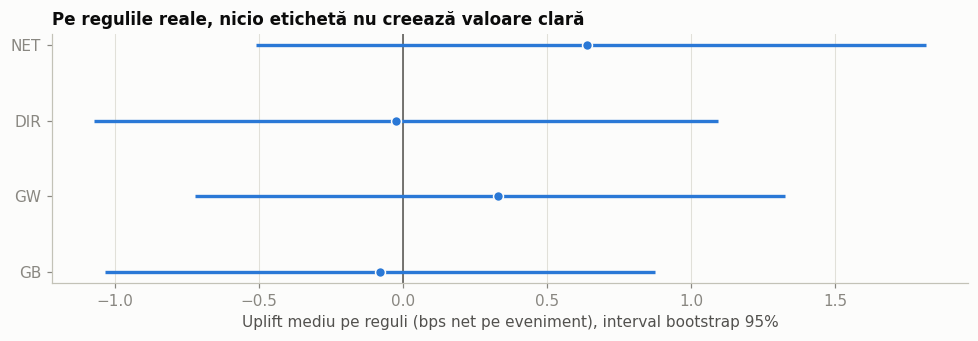

In [10]:
TEST_DAYS = pd.date_range(FIRST_TEST, TEST_END, freq="D", inclusive="left"); N_DAYS = len(TEST_DAYS)
_r = np.random.default_rng(SEED + 7)
BW = np.zeros((BOOT_REPS, N_DAYS))
for r_ in range(BOOT_REPS):
    for s_ in _r.integers(0, N_DAYS, int(np.ceil(N_DAYS / BOOT_BLOCK_D))):
        BW[r_, (s_ + np.arange(BOOT_BLOCK_D)) % N_DAYS] += 1

def day_index(t):
    return ((np.asarray(t) - FIRST_TEST.value) // (86400 * 10**9)).astype(np.int64)

def ratio_boot(num, den, day):
    a = np.bincount(day, weights=num, minlength=N_DAYS); b = np.bincount(day, weights=den, minlength=N_DAYS)
    return (BW @ a) / (BW @ b)

def real_cell(key):
    c = CELLS[key]; E = c["E"]
    W = walk_forward(E, c["X"].astype(np.float64))
    if W is None or E["y"].to_numpy()[W["te"]].min() == E["y"].to_numpy()[W["te"]].max():
        return None
    row = dict(strategy=key[0], bars=key[1], **summarise(E, W))
    te = W["te"]; o = np.argsort(E["t0_ns"].to_numpy()[te], kind="stable")
    t0, t1 = E["t0_ns"].to_numpy()[te][o], E["t1_ns"].to_numpy()[te][o]; net = E["net_bps"].to_numpy()[te][o]; day = day_index(t0)
    month = E["month"].to_numpy()[te][o]
    rng = np.random.default_rng(int(hashlib.md5(str(key).encode()).hexdigest()[:8], 16))
    groups = [np.flatnonzero(month == m) for m in np.unique(month)]
    boots = {}
    for lab in LABELS:
        k = W["k_" + lab][o].astype(np.bool_)
        boots[lab] = ratio_boot(np.where(k, net, 0), k.astype(float), day) - ratio_boot(net, np.ones(net.size), day)
        tk = greedy(t0, t1, k)
        real = net[tk].mean() if tk.any() else np.nan
        rnd = np.empty(RANDOM_FILTER_REPS)
        for r in range(RANDOM_FILTER_REPS):
            kk = np.zeros(net.size, np.bool_)
            for g_ in groups:
                c_ = int(k[g_].sum())
                if c_:
                    kk[rng.choice(g_, c_, replace=False)] = True
            t_ = greedy(t0, t1, kk); rnd[r] = net[t_].mean() if t_.any() else np.nan
        row[f"{lab}_pct"] = float(np.nanmean(rnd < real)); row[f"{lab}_rand"] = float(np.nanmean(rnd))
    return row, boots

KEYS = [(k, b) for k in NAMES for b in ALL_BARS]
t_ = time.time()
_a = [x for x in cached("partA", lambda: pmap(real_cell, KEYS, key=lambda k: len(CELLS[k]["E"]))) if x is not None]
A = pd.DataFrame([x[0] for x in _a]); ABOOT = {(x[0]["strategy"], x[0]["bars"]): x[1] for x in _a}
real = [k for k in NAMES if STRATS[k][0][0] != "0"]
print(f"Part A: {len(A)} cells in {(time.time() - t_) / 60:.1f} min.")
AR = A[A["strategy"].isin(real)]
rows = []
keys_r = [k for k in ABOOT if k[0] in real]
for lab in LABELS:
    per_rule = np.stack([np.nanmean(np.stack([ABOOT[k][lab] for k in keys_r if k[0] == s]), axis=0) for s in real if any(k[0] == s for k in keys_r)])
    b = np.nanmean(per_rule, axis=0)
    b0 = np.nanmean(np.stack([np.nanmean(np.stack([ABOOT[k]["NET"] for k in keys_r if k[0] == s]), axis=0) for s in real if any(k[0] == s for k in keys_r)]), axis=0)
    rows.append(dict(label=lab, retention=AR[f"{lab}_ret"].mean(), auc_net=AR[f"{lab}_auc_net"].mean(), auc_dir=AR[f"{lab}_auc_dir"].mean(), auc_barrier=AR[f"{lab}_auc_barrier"].mean(), ic_gross=AR[f"{lab}_ic"].mean(),
                     gross_kept=AR[f"{lab}_gross_kept"].mean(), net_kept=AR[f"{lab}_net_kept"].mean(), uplift=AR.groupby("strategy")[f"{lab}_uplift"].mean().mean(), lo=np.nanquantile(b, .025), hi=np.nanquantile(b, .975), d_vs_net_lo=np.nanquantile(b - b0, .025), d_vs_net_hi=np.nanquantile(b - b0, .975),
                     cells_p95=float((AR[f"{lab}_pct"] >= .95).mean()), mean_pct=AR[f"{lab}_pct"].mean(), cells_net_pos=int((AR[f"{lab}_sim_net"] > 0).sum())))
ATAB = pd.DataFrame(rows).set_index("label")
display(ATAB.round(3))
print(f"Unfiltered, mean over real cells: gross {AR['gross_all'].mean():.2f}, net {AR['net_all'].mean():.2f}. Expected-value rule on GB: keeps {AR['EV_ret'].mean():.1%}, net kept {AR['EV_net_kept'].mean():.2f}, cells with at least 30 kept {int((AR['EV_n'] >= 30).sum())}, of which net positive {int(((AR['EV_n'] >= 30) & (AR['EV_net_kept'] > 0)).sum())}.")
BYR = pd.DataFrame({lab: AR.groupby("strategy")[f"{lab}_uplift"].mean() for lab in LABELS}).reindex(real)
BYR["edge test"] = AR.groupby("strategy")["gross_all"].mean(); BYR["best net kept"] = pd.DataFrame({lab: AR.groupby("strategy")[f"{lab}_net_kept"].mean() for lab in LABELS}).max(axis=1)
display(BYR.round(1))
print("Rule x label combinations with mean percentile against random of at least 0.80:", [(s, l, round(AR[AR["strategy"] == s][f"{l}_pct"].mean(), 2)) for s in real for l in LABELS if AR[AR["strategy"] == s][f"{l}_pct"].mean() >= .8])

fig, ax = plt.subplots(figsize=(9, 3.2))
yy = np.arange(len(LABELS))[::-1]
ax.axvline(0, color=INK2, lw=1)
ax.hlines(yy, ATAB["lo"], ATAB["hi"], color=C["blue"], lw=2.2)
ax.scatter(ATAB["uplift"], yy, s=42, color=C["blue"], edgecolor=SURFACE, zorder=3)
ax.set_yticks(yy); ax.set_yticklabels(LABELS); ax.grid(axis="y", visible=False)
ax.set_xlabel("Uplift mediu pe reguli (bps net pe eveniment), interval bootstrap 95%"); ax.set_title("Pe regulile reale, nicio etichetă nu creează valoare clară")
fig.tight_layout(); plt.show()

**Interpretare.**

* **Nicio etichetă nu e mai bună decât `NET`.** Toate uplift-urile au intervale care includ zero (`NET` +0.6 [−0.5, +1.8]), iar diferențele față de `NET` includ și ele zero. Predicția P5 se confirmă.
* **Percentila față de filtrul aleator e puțin peste 0.5** (0.54–0.59). Pentru `NET`, 10.5% din celule depășesc percentila 95, față de 5% așteptat. Cele 9 seturi de bare ale unei reguli sunt aproape aceleași tranzacții, deci excesul vine din câteva reguli (`FLOWC`, `LIQREV`, `DON6H`, `TSCAN`), nu din 16 celule independente. Criteriul fixat cerea un exces clar, deci verdictul rămâne negativ.
* **Etichetele direcționale nu găsesc direcție:** AUC pe direcție 0.498–0.500 pentru toate.
* **Regula de valoare așteptată pe `GB` păstrează doar 11% din tranzacții** și tot pierde (−10.9 bps). Dintre cele 99 de celule cu cel puțin 30 de tranzacții păstrate, 13 au net pozitiv: cam cât ar da hazardul la un `edge` de −2 bps și zgomot de câteva zeci de bps.
* **`TSCAN` și `LIQREV` rămân cele mai bune** (cel mai bun net păstrat −1.3 și −7.9 bps), la fel ca în notebook-ul anterior. Rămân ipoteze pentru date noi.

## 6. Partea B: primarele sintetice

Construiesc un fond de momente aleatoare (30 pe zi) pe fiecare set de bare și rezolv fiecare moment **pe ambele părți**. Features se calculează separat pentru long și short, ca orientarea să fie exactă. Fiecare replică alege momente din fond și partea dată de oracol, apoi reconstruiește features care depind de istoricul primarei (`recent_hit_20`, timpul de la evenimentul anterior).

In [11]:
POOL_RATE = 30
H_SYN = 4 * 3600
SYN_BARS = ["time_1m", "volume_adapt60s", "cusum_adapt_c1"]
Q_GRID = [.50, .54, .58, .62, .66, .70]
RATES = [1, 3, 9]
N_REP, N_REP_BARS = (2, 1) if DRY_RUN else (16, 8)
if DRY_RUN:
    Q_GRID = [.50, .62, .70]; RATES = [3, 9]
REGIME_FEATS = ["oi_chg_4h", "l_fano_15m", "rel_depth_10bps", "sign_acf_1", "large_share_15m"]
SYN_BARS = [b for b in SYN_BARS if b in ALL_BARS]
_cols = ["side", "t0_ns", "t1_ns", "reason", "gross_bps", "fund_bps", "net_bps", "y", "width"]

def build_pool(bar):
    r = np.random.default_rng(SEED + 500)
    tt = np.sort(r.integers(TRAIN_START.value, DATA_END.value, POOL_RATE * (DATA_END - TRAIN_START).days))
    b = load_bars(bar, ["decision_time_ns", "t_start_ns", "eval_time_ns", "complete", "feed_complete", "last_trade_age_ms"])
    t = b["decision_time_ns"].to_numpy()
    pos = np.unique(np.searchsorted(t, tt, side="left")); pos = pos[pos < t.size]
    good = (b["complete"].to_numpy()[pos] == 1) & (b["feed_complete"].to_numpy()[pos] == 1) & (b["last_trade_age_ms"].to_numpy()[pos] <= FRESH_MS)
    pos = pos[good]
    args = (b["decision_time_ns"].to_numpy()[pos], b["t_start_ns"].to_numpy()[pos], b["eval_time_ns"].to_numpy()[pos], H_SYN, np.zeros(pos.size))
    EL = label_events(pos, np.ones(pos.size, np.int64), *args).assign(dur_norm=np.nan)
    ES = label_events(pos, -np.ones(pos.size, np.int64), *args).assign(dur_norm=np.nan)
    Rr = read_rows(bar, pos)
    FL, FS = candidate_features(EL, Rr), candidate_features(ES, Rr)
    ok = eligibility(EL, Rr, FL, H_SYN) & EL["fill_ok"].to_numpy() & ES["fill_ok"].to_numpy()
    return dict(L=EL[ok].reset_index(drop=True), S=ES[ok].reset_index(drop=True), XL=FL[FEATS].to_numpy(np.float32)[ok], XS=FS[FEATS].to_numpy(np.float32)[ok])

t_ = time.time()
POOLS = dict(zip(SYN_BARS, cached("pools", lambda: pmap(build_pool, SYN_BARS, workers=3))))
for bar, P in POOLS.items():
    gl, gs = P["L"]["gross_bps"].to_numpy(), P["S"]["gross_bps"].to_numpy()
    P["d"] = np.where(gl >= gs, 1, -1)
    P["absg"] = float(np.mean(np.maximum(gl, gs)))
    P["width"] = P["L"]["width"].to_numpy()
    P["kappa"] = float(np.mean(np.maximum(gl, gs) / (1e4 * P["width"])))
    t0 = P["L"]["t0_ns"].to_numpy()
    dev = t0 < FIRST_TEST.value
    P["med"] = {f: float(np.nanmedian(P["XL"][dev, FIDX[f]])) for f in REGIME_FEATS}
    print(f"{bar}: {len(gl):,} moments, cost of crossing both sides {np.mean(gl + gs):+.1f} bps, mean winning-side gross {P['absg']:.1f} bps.")
# Orientation check: the two feature matrices must be exact opposites on signed columns.
_P = POOLS[SYN_BARS[0]]
_j = [j for j, c in enumerate(FEATS) if c.startswith("s_")]
assert np.nanmax(np.abs(_P["XL"][:, _j] + _P["XS"][:, _j])) < 1e-4
assert np.allclose(_P["XL"][:, FIDX["z_adverse_15m"]], _P["XS"][:, FIDX["z_favorable_15m"]], equal_nan=True)
print(f"Pools ready in {time.time() - t_:.0f} s.")

def make_primary(bar, kind, qbar, rate, seed):
    P = POOLS[bar]; r = np.random.default_rng(seed)
    n = len(P["L"])
    idx = np.sort(r.choice(n, int(n * rate / POOL_RATE), replace=False))     # the rate is before eligibility, as for the pool
    d = P["d"][idx]
    if kind == "HIT":
        q = np.full(idx.size, qbar)
    elif kind == "BPS":
        # Constant expected edge in bps: hit rate falls where the barrier is wide.
        q = np.clip(.5 + (qbar - .5) * P["absg"] / (1e4 * P["kappa"] * P["width"][idx]), .5, .98)
    else:
        f = REGIME_FEATS[r.integers(len(REGIME_FEATS))]
        x = P["XL"][idx, FIDX[f]]
        q = np.where(x > P["med"][f], .5 + 2 * (qbar - .5), .5)
    side = np.where(r.random(idx.size) < q, d, -d)
    isL = side > 0
    E = pd.DataFrame({c: np.where(isL, P["L"][c].to_numpy()[idx], P["S"][c].to_numpy()[idx]) for c in _cols})
    E["side"] = side; E["fill_ok"] = True; E["eligible"] = True
    E["crash"] = (E["t1_ns"].to_numpy() >= CRASH_START.value) & (E["t0_ns"].to_numpy() < CRASH_END.value)
    X = np.where(isL[:, None], P["XL"][idx], P["XS"][idx]).astype(np.float64)
    t0 = E["t0_ns"].to_numpy()
    X[:, FIDX["l_since_prev"]] = np.log1p(np.diff(t0.astype(float), prepend=np.nan) / 3.6e12)
    X[:, FIDX["l_events_24h"]] = np.log1p(np.arange(len(E)) - np.searchsorted(t0, t0 - 24 * 3600 * 10**9))
    X[:, FIDX["recent_hit_20"]], X[:, FIDX["recent_pnl_20"]] = recent_primary_state(E)
    return E, X

def syn_job(job):
    bar, kind, qbar, rate, rep = job
    seed = int(hashlib.md5(str((kind, qbar, rate, rep, bar)).encode()).hexdigest()[:8], 16)
    E, X = make_primary(bar, kind, qbar, rate, seed)
    W = walk_forward(E, X)
    if W is None:
        return None
    tr, _ = block_index(E, 0)
    u = time_uniqueness(E["t0_ns"].to_numpy()[tr], E["t1_ns"].to_numpy()[tr]).sum() if tr.size else 0
    return dict(bars=bar, kind=kind, q=qbar, rate=rate, rep=rep, neff_first=float(u), **summarise(E, W))

JOBS = [("time_1m" if "time_1m" in SYN_BARS else SYN_BARS[0], k, q, r, i) for k in ("HIT", "BPS", "REGIME") for q in Q_GRID for r in RATES for i in range(N_REP)]
JOBS += [(b, k, q, RATES[len(RATES) // 2], i) for b in SYN_BARS[1:] for k in ("HIT", "BPS", "REGIME") for q in Q_GRID for i in range(N_REP_BARS)]
t_ = time.time()
SYN = pd.DataFrame([x for x in cached("syn", lambda: pmap(syn_job, JOBS, key=lambda j: j[3])) if x is not None])
print(f"Part B: {len(SYN)} synthetic primaries in {(time.time() - t_) / 60:.1f} min.")

time_1m: 12,306 moments, cost of crossing both sides -1.9 bps, mean winning-side gross 51.8 bps.
volume_adapt60s: 12,151 moments, cost of crossing both sides -1.6 bps, mean winning-side gross 52.1 bps.
cusum_adapt_c1: 11,861 moments, cost of crossing both sides -1.7 bps, mean winning-side gross 52.5 bps.
Pools ready in 10 s.


Part B: 1152 synthetic primaries in 9.1 min.


### 6.1 Rezultatul principal: valoarea filtrului în funcție de `edge` `EXPLORATORY`

Toate graficele folosesc `edge`-ul brut **realizat în test**, nu `q`. Punctele sunt medii pe replici, iar benzile arată ±1 deviație standard între replici. Uplift-ul e bps net pe eveniment păstrat minus bps net pe toate evenimentele, la retenție de 50%.

n_test  neff_first  gross_all  net_all  NET_uplift  DIR_uplift  GW_uplift  GB_uplift  NET_auc_net  NET_auc_dir  DIR_auc_dir  skill_net
kind   rate q                                                                                                                                           
BPS    1    0.50   228.0       168.0       -2.0    -12.0        -1.0        -2.0       -3.1       -1.0        0.503        0.475        0.482    -0.0045
            0.54   220.0       174.0        3.2     -6.8         0.4         1.3        0.7        0.7        0.513        0.508        0.514    -0.0045
            0.58   228.0       168.0        6.4     -3.6        -0.4        -0.2       -0.5       -1.5        0.506        0.485        0.508    -0.0062
            0.62   229.0       166.0       11.8      1.8         1.1         0.9        1.4        1.1        0.515        0.517        0.538    -0.0018
            0.66   229.0       166.0       15.7      5.7         0.6        -1.0       -0.6       -0.8        0.521        0.532        0.543    -0.0018
            0.70   228.0       168.0       19.2      9.2        -0.6        -0.7       -0.4       -1.3        0.514        0.522        0.537    -0.0033
       3    0.50   681.0       443.0       -0.5    -10.5        -0.2         0.8       -0.5        0.2        0.509        0.482        0.507    -0.0023
            0.54   678.0       445.0        3.5     -6.5         0.1        -0.8       -0.2       -0.2        0.511        0.490        0.503    -0.0013
            0.58   678.0       446.0        6.8     -3.2         0.4         0.5       -0.1       -0.7        0.510        0.497        0.521    -0.0015
            0.62   679.0       445.0       12.0      2.0         0.7         0.1       -0.4       -0.1        0.524        0.516        0.546    -0.0004
            0.66   684.0       445.0       16.1      6.1         1.6         0.1        1.0        0.9        0.535        0.545        0.568    -0.0010
            0.70   690.0       438.0       20.8     10.8         1.3        -0.1        1.0        0.9        0.547        0.556        0.604     0.0013
       9    0.50  2033.0       965.0       -1.0    -11.0        -0.8         0.6       -0.3        0.0        0.516        0.487        0.514    -0.0001
            0.54  2050.0       960.0        2.9     -7.1         0.2         0.2        0.2        0.1        0.512        0.492        0.515    -0.0000
            0.58  2052.0       961.0        7.4     -2.6         0.8         1.1        0.6        0.9        0.523        0.501        0.538     0.0006
            0.62  2042.0       961.0       11.9      1.9         1.3         0.1        0.5        1.3        0.535        0.523        0.553     0.0016
            0.66  2057.0       962.0       16.3      6.3         1.1         0.3        0.8        0.9        0.543        0.551        0.588     0.0019
            0.70  2044.0       964.0       20.4     10.4         1.9         0.3        1.8        2.3        0.562        0.583        0.618     0.0057
HIT    1    0.50   224.0       171.0        1.7     -8.3         1.7         0.7        0.9        2.4        0.520        0.506        0.517    -0.0078
            0.54   229.0       167.0        3.6     -6.5         1.5        -0.3       -0.5       -0.7        0.509        0.487        0.477    -0.0106
            0.58   229.0       167.0        8.8     -1.2         1.8         0.4        0.2       -0.5        0.507        0.489        0.489    -0.0053
            0.62   227.0       168.0       13.9      3.9         1.6         3.9        3.1        3.1        0.514        0.495        0.510    -0.0056
            0.66   223.0       171.0       16.0      6.0         1.5        -0.1        0.2        2.8        0.516        0.496        0.498    -0.0037
            0.70   227.0       167.0       23.8     13.8         2.6        -1.8       -0.9        2.2        0.516        0.478        0.463    -0.0009
       3    0.50   682.0       446.0    

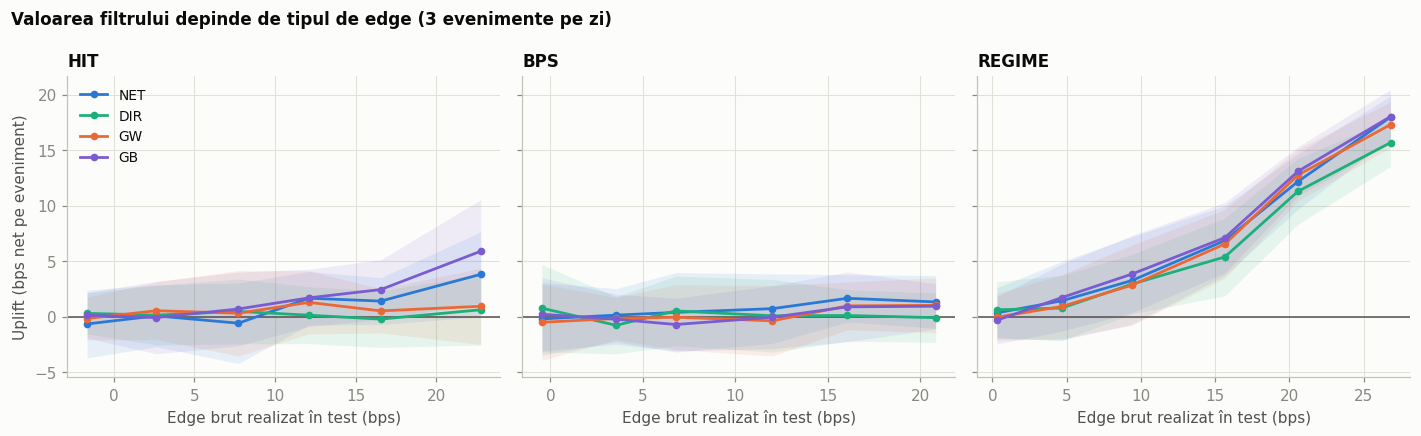

In [12]:
MAIN_BAR = "time_1m" if "time_1m" in SYN_BARS else SYN_BARS[0]
S1 = SYN[SYN["bars"] == MAIN_BAR]
KINDS = ["HIT", "BPS", "REGIME"]
LAB_COL = {"NET": C["blue"], "DIR": C["aqua"], "GW": C["orange"], "GB": C["purple"]}
agg = {"gross_all": "mean", "net_all": "mean", "base_test": "mean", "neff_first": "mean", "n_test": "mean", "skill_net": "mean", **{f"{l}_{m}": "mean" for l in LABELS for m in ("uplift", "net_kept", "gross_kept", "auc_net", "auc_dir", "auc_barrier", "ic", "ret")}}
T1 = S1.groupby(["kind", "rate", "q"]).agg(agg)
SD = S1.groupby(["kind", "rate", "q"])[[f"{l}_uplift" for l in LABELS]].std()
show = T1[["n_test", "neff_first", "gross_all", "net_all", "NET_uplift", "DIR_uplift", "GW_uplift", "GB_uplift", "NET_auc_net", "NET_auc_dir", "DIR_auc_dir", "skill_net"]]
display(show.round({"n_test": 0, "neff_first": 0, "gross_all": 1, "net_all": 1, "NET_uplift": 1, "DIR_uplift": 1, "GW_uplift": 1, "GB_uplift": 1, "NET_auc_net": 3, "NET_auc_dir": 3, "DIR_auc_dir": 3, "skill_net": 4}))

rmid = RATES[len(RATES) // 2]
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, k in zip(axes, KINDS):
    ax.axhline(0, color=INK2, lw=1)
    d = T1.loc[(k, rmid)]; sd = SD.loc[(k, rmid)]
    for l in LABELS:
        ax.plot(d["gross_all"], d[f"{l}_uplift"], marker="o", ms=4, color=LAB_COL[l], label=l)
        ax.fill_between(d["gross_all"], d[f"{l}_uplift"] - sd[f"{l}_uplift"], d[f"{l}_uplift"] + sd[f"{l}_uplift"], color=LAB_COL[l], alpha=.10, lw=0)
    ax.set_title(k); ax.set_xlabel("Edge brut realizat în test (bps)")
axes[0].set_ylabel("Uplift (bps net pe eveniment)"); axes[0].legend(loc="upper left")
fig.suptitle(f"Valoarea filtrului depinde de tipul de edge ({rmid} evenimente pe zi)", x=.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout(); plt.show()

**Interpretare.**

* **Fără `edge` nu e nimic de câștigat.** La `q = 0.5` uplift-ul e în jur de zero pe toate tipurile, etichetele și frecvențele.
* **`HIT`: volatilitatea devine bani, dar puțin.** Uplift-ul `GB` crește cu `edge`-ul la 3 și 9 evenimente pe zi (+5.9 și +5.2 bps la ~22 bps de `edge`; Spearman 0.94 și 1.00), iar `DIR` stă la zero. La 1 eveniment pe zi zgomotul acoperă efectul. P1 se confirmă la 2 din 3 frecvențe, nu la toate, deci doar parțial după criteriul fixat.
* **`BPS`: aproape nimic**, sub 2.3 bps chiar la 21 bps de `edge`. Când fiecare tranzacție aduce același număr de bps, a alege tranzacțiile mai volatile nu ajută. P2 se confirmă.
* **`REGIME`: mult.** Uplift +3 la +4.5 bps la 9 bps de `edge` și +16 la +18 bps la 27 bps. P3 se confirmă pentru `edge` și N.
* **`DIR` nu bate `NET`**, contrar predicției P3. `NET` și `GB` sunt egale sau mai bune. Un model care vede regimul îl găsește prin orice etichetă, iar `DIR` pierde un sfert din date (ieșirile pe timp).

### 6.2 AUC și log loss spun asta? `EXPLORATORY`

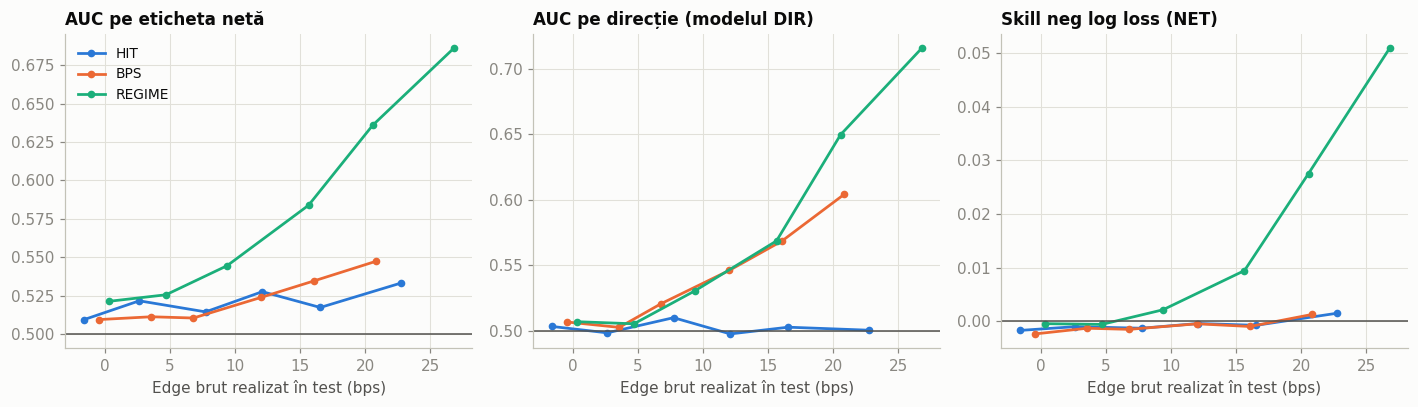

rho(edge, NET auc)  rho(edge, DIR auc)  rho(edge, NET uplift)  rho(edge, GB uplift)  rho(edge, skill)
kind   rate                                                                                                       
HIT    1                   0.09               -0.49                   0.14                  0.31              0.89
       3                   0.71               -0.26                   0.89                  0.94              0.89
       9                   0.77               -0.94                   0.94                  1.00              0.83
BPS    1                   0.77                0.77                   0.31                 -0.09              0.60
       3                   0.94                0.94                   0.94                  0.60              0.89
       9                   0.94                1.00                   0.94                  0.94              1.00
REGIME 1                   0.94                0.77                   0.94                  0.94              0.94
       3                   1.00                0.94                   1.00                  1.00              0.94
       9                   1.00                1.00                   1.00                  1.00              1.00

At the highest edge:


gross_all  NET_auc_net  NET_auc_barrier  NET_auc_dir  DIR_auc_dir  NET_uplift  GB_uplift  skill_net
kind   rate                                                                                                     
BPS    1        19.215        0.514            0.551        0.522        0.537      -0.583     -1.306     -0.003
       3        20.844        0.547            0.589        0.556        0.604       1.316      0.926      0.001
       9        20.373        0.562            0.627        0.583        0.618       1.903      2.268      0.006
HIT    1        23.818        0.516            0.534        0.478        0.463       2.591      2.225     -0.001
       3        22.741        0.533            0.562        0.494        0.500       3.806      5.888      0.002
       9        21.739        0.532            0.578        0.491        0.504       3.209      5.226      0.001
REGIME 1        27.230        0.653            0.553        0.678        0.646      14.065     16.310      0.025
       3        26.805        0.686            0.569        0.711        0.715      17.991     18.036      0.051
       9        28.179        0.697            0.568        0.724        0.731      17.421     18.057      0.058

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for k, col in zip(KINDS, (C["blue"], C["orange"], C["aqua"])):
    d = T1.loc[(k, rmid)]
    axes[0].plot(d["gross_all"], d["NET_auc_net"], marker="o", ms=4, color=col, label=k)
    axes[1].plot(d["gross_all"], d["DIR_auc_dir"], marker="o", ms=4, color=col, label=k)
    axes[2].plot(d["gross_all"], d["skill_net"], marker="o", ms=4, color=col, label=k)
axes[0].set_title("AUC pe eticheta netă"); axes[1].set_title("AUC pe direcție (modelul DIR)"); axes[2].set_title("Skill neg log loss (NET)")
for ax in axes[:2]:
    ax.axhline(.5, color=INK2, lw=1)
axes[2].axhline(0, color=INK2, lw=1)
for ax in axes:
    ax.set_xlabel("Edge brut realizat în test (bps)")
axes[0].legend()
fig.tight_layout(); plt.show()
rows = []
for k in KINDS:
    for r_ in RATES:
        d = T1.loc[(k, r_)]
        rows.append(dict(kind=k, rate=r_, **{f"rho(edge, {m})": stats.spearmanr(d["gross_all"], d[c])[0] for m, c in (("NET auc", "NET_auc_net"), ("DIR auc", "DIR_auc_dir"), ("NET uplift", "NET_uplift"), ("GB uplift", "GB_uplift"), ("skill", "skill_net"))}))
display(pd.DataFrame(rows).set_index(["kind", "rate"]).round(2))
same = T1.xs(Q_GRID[-1], level="q")
print("At the highest edge:"); display(same[["gross_all", "NET_auc_net", "NET_auc_barrier", "NET_auc_dir", "DIR_auc_dir", "NET_uplift", "GB_uplift", "skill_net"]].round(3))

**Interpretare.**

* **AUC-ul e un ghid slab pentru valoare (P4 confirmat).** Exemplele cele mai clare, la ~21 bps de `edge` și 9 evenimente pe zi:
  * `BPS`: AUC pe direcție **0.62**, uplift **+2.3 bps**. Modelul învață corect că oracolul greșește mai des când bariera e lată, dar asta nu schimbă bps-ul mediu.
  * `HIT`: AUC pe direcție **0.50**, uplift `GB` **+5.2 bps**. Nimic de ghicit despre direcție, totuși bani din volatilitate.
* **AUC-ul pe eticheta netă crește cu `edge`-ul chiar și la `BPS`** (Spearman 0.94 la 3 și 9 pe zi), unde valoarea economică nu crește.
* **Log loss-ul se comportă la fel.** Skill-ul trece pe pozitiv peste ~12 bps de `edge` la toate tipurile, inclusiv la `BPS`. Ambele metrici răspund la cât de previzibilă e eticheta, nu la cât valorează previziunea.
* **`REGIME` e singurul caz în care AUC-ul și banii merg împreună** (AUC 0.73 și +18 bps la 27 bps).

### 6.3 Cât `edge` trebuie ca să meargă? `EXPLORATORY`

Două praguri: de la ce `edge` brut devine netul pozitiv **fără** filtru și **cu** cel mai bun filtru fixat dinainte (`GB`, 50%). Diferența e `edge`-ul pe care modelul secundar îl economisește.

neff  unfiltered  filter NET  filter DIR  filter GW  filter GB
kind   rate                                                                 
HIT    1     168.3        10.0         8.3         9.2        9.4        9.8
       3     447.4        10.0         9.6         9.7        9.3        9.0
       9     961.8        10.0         9.1        10.5       10.2        8.9
BPS    1     168.4        10.0         9.5         9.6        9.5        9.8
       3     443.5        10.0         9.5         9.8       10.3       10.3
       9     962.4        10.0         9.0         9.3        9.4        9.0
REGIME 1     165.6        10.0         8.0         8.4        8.0        8.3
       3     444.0        10.0         7.5         7.8        7.8        7.2
       9     962.9        10.0         7.1         7.7        7.4        6.9

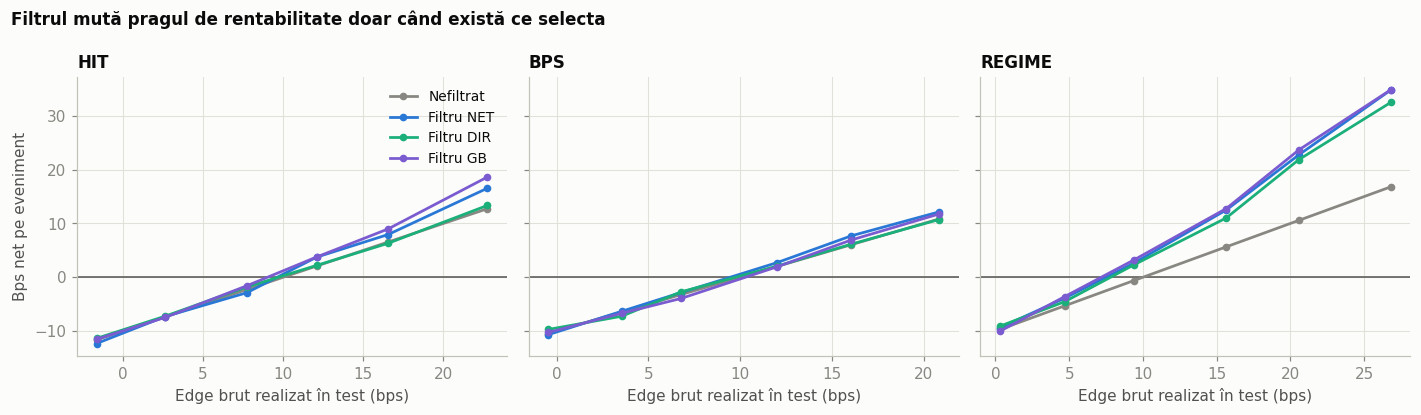

In [14]:
def crossing(x, y):
    # First zero crossing by linear interpolation.
    x, y = np.asarray(x), np.asarray(y)
    o = np.argsort(x); x, y = x[o], y[o]
    for i in range(len(x) - 1):
        if y[i] < 0 <= y[i + 1]:
            return x[i] + (x[i + 1] - x[i]) * (-y[i]) / (y[i + 1] - y[i])
    return np.nan
rows = []
for k in KINDS:
    for r_ in RATES:
        d = T1.loc[(k, r_)]
        rows.append(dict(kind=k, rate=r_, neff=d["neff_first"].mean(), unfiltered=crossing(d["gross_all"], d["net_all"]), **{f"filter {l}": crossing(d["gross_all"], d[f"{l}_net_kept"]) for l in LABELS}))
BRK = pd.DataFrame(rows).set_index(["kind", "rate"])
display(BRK.round(1))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, k in zip(axes, KINDS):
    d = T1.loc[(k, rmid)]
    ax.axhline(0, color=INK2, lw=1)
    ax.plot(d["gross_all"], d["net_all"], marker="o", ms=4, color=MUTED, label="Nefiltrat")
    for l in ("NET", "DIR", "GB"):
        ax.plot(d["gross_all"], d[f"{l}_net_kept"], marker="o", ms=4, color=LAB_COL[l], label=f"Filtru {l}")
    ax.set_title(k); ax.set_xlabel("Edge brut realizat în test (bps)")
axes[0].set_ylabel("Bps net pe eveniment"); axes[0].legend()
fig.suptitle("Filtrul mută pragul de rentabilitate doar când există ce selecta", x=.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout(); plt.show()

**Interpretare.**

* **Fără filtru, netul devine pozitiv de la 10 bps brut**, adică exact costul. Asta e așteptat și confirmă că simularea e consistentă.
* **Filtrul economisește puțin:**
  * `HIT`: în jur de 1 bps (pragul scade la ~9 bps).
  * `BPS`: în jur de 0.5–1 bps.
  * `REGIME`: 2–3 bps (pragul scade la ~7 bps), mai mult la N mare.
* **Practic, un model secundar nu salvează o primară fără `edge` brut aproape de cost.** Pentru regulile reale, cu `edge` între −5.5 și +3.8 bps, ar trebui să existe un regim cu `edge` mult mai mare decât media, pe care features să-l vadă. Nu l-am găsit.

### 6.4 `Edge` și N, separat `EXPLORATORY`

Aici se poate răspunde la întrebarea de la început: cele două axe sunt variate independent, deci regresia nu mai are problema regulilor reale. Erorile sunt clusterizate pe replică.

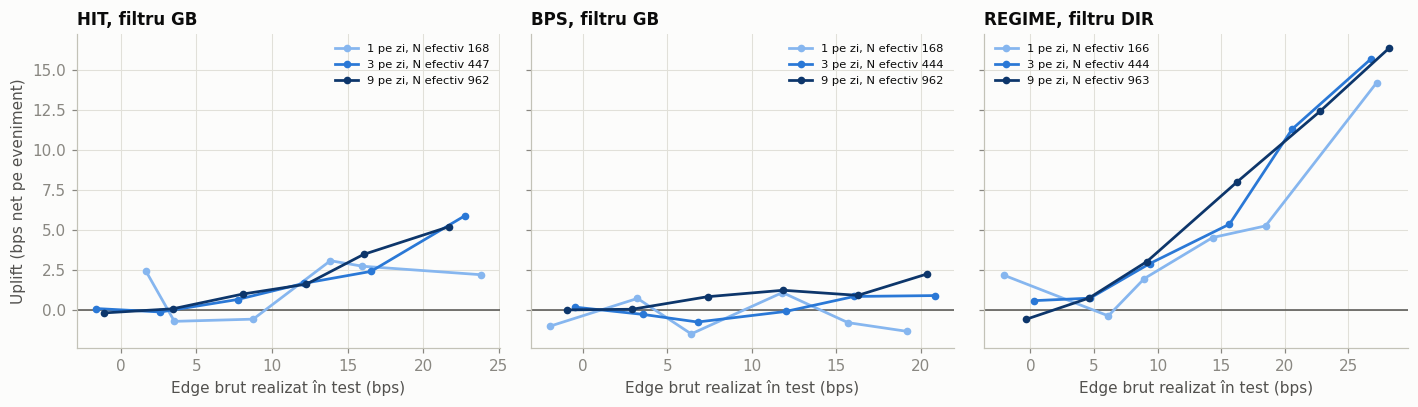

edge per 10 bps          log N   edge x log N    R2
HIT    NET_auc_net   +0.004 (+2.8)  +0.006 (+2.1)  +0.006 (+2.5)  0.05
       DIR_auc_dir   -0.004 (-1.2)  +0.011 (+4.3)  +0.002 (+0.4)  0.05
       NET_uplift    +1.267 (+5.5)  -0.304 (-0.8)  +0.895 (+2.0)  0.11
       DIR_uplift    -0.052 (-0.2)  -0.240 (-0.8)  +0.106 (+0.2)   0.0
       GB_uplift     +2.082 (+7.8)  +0.333 (+1.1)  +0.671 (+1.8)  0.18
BPS    NET_auc_net   +0.014 (+5.8)  +0.011 (+4.3)  +0.011 (+3.8)   0.2
       DIR_auc_dir   +0.034 (+8.0)  +0.018 (+5.1)  +0.020 (+3.6)  0.32
       NET_uplift    +0.636 (+2.4)  +0.394 (+1.3)  +0.468 (+1.4)  0.04
       DIR_uplift    -0.391 (-1.2)  +0.417 (+1.3)  +0.224 (+0.5)  0.02
       GB_uplift     +0.258 (+0.9)  +0.714 (+3.0)  +0.775 (+1.7)  0.05
REGIME NET_auc_net  +0.054 (+37.8)  +0.015 (+6.9)  +0.012 (+3.6)  0.74
       DIR_auc_dir  +0.059 (+16.8)  +0.027 (+9.2)  +0.022 (+4.6)  0.59
       NET_uplift   +5.573 (+33.5)  +0.535 (+2.3)  +1.012 (+2.8)   0.7
       DIR_uplift   +4.735 (+19.1)  +0.840 (+2.9)  +1.306 (+2.9)  0.57
       GB_uplift    +5.931 (+36.5)  +0.588 (+2.3)  +0.679 (+2.5)  0.72

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
shades = {RATES[0]: "#86b6ef", RATES[len(RATES) // 2]: "#2a78d6", RATES[-1]: "#0d366b"}
for ax, k in zip(axes, KINDS):
    ax.axhline(0, color=INK2, lw=1)
    for r_ in RATES:
        d = T1.loc[(k, r_)]
        ax.plot(d["gross_all"], d["DIR_uplift" if k == "REGIME" else "GB_uplift"], marker="o", ms=4, color=shades[r_], label=f"{r_} pe zi, N efectiv {d['neff_first'].mean():.0f}")
    ax.set_title(f"{k}, filtru {'DIR' if k == 'REGIME' else 'GB'}"); ax.set_xlabel("Edge brut realizat în test (bps)"); ax.legend(fontsize=7.5)
axes[0].set_ylabel("Uplift (bps net pe eveniment)")
fig.tight_layout(); plt.show()
rows = {}
S1c = S1.assign(edge10=S1["gross_all"] / 10, logn=np.log(S1["neff_first"]), grp=S1["rep"].astype(str))
for k in KINDS:
    d = S1c[S1c["kind"] == k]
    d = d.assign(ex=(d["edge10"] - d["edge10"].mean()) * (d["logn"] - d["logn"].mean()))
    for dep in ("NET_auc_net", "DIR_auc_dir", "NET_uplift", "DIR_uplift", "GB_uplift"):
        f = sm.OLS(d[dep], sm.add_constant(d[["edge10", "logn", "ex"]]), missing="drop").fit(cov_type="cluster", cov_kwds={"groups": d.dropna(subset=[dep])["grp"].astype("category").cat.codes})
        rows[(k, dep)] = {"edge per 10 bps": f"{f.params['edge10']:+.3f} ({f.tvalues['edge10']:+.1f})", "log N": f"{f.params['logn']:+.3f} ({f.tvalues['logn']:+.1f})", "edge x log N": f"{f.params['ex']:+.3f} ({f.tvalues['ex']:+.1f})", "R2": round(f.rsquared, 2)}
display(pd.DataFrame(rows).T)

**Interpretare. Acum `edge` și N sunt separate curat.**

* **`REGIME`:** `edge`-ul domină (+5.6 bps uplift la 10 bps de `edge`, t 34), N ajută (+0.5 la log N, t 2.3), iar interacțiunea e pozitivă (t 2.8). Mai multe date contează mai mult când `edge`-ul e mai mare.
* **Exemplu concret la 9 bps de `edge`:** uplift `GB` +2.3, +3.8, +4.5 bps la 165, 440 și 960 de evenimente efective. Deviația standard între replici scade de la 4–6 bps la 1.3–2.6 bps. La N mic efectul există, dar o singură replică, adică o singură strategie reală, îl poate rata ușor.
* **`HIT`:** uplift-ul `GB` crește cu `edge`-ul (t 7.8), iar N contează puțin.
* **`BPS`:** aproape nimic, oricât de mare e N.
* **Legătura cu temerea din notebook-ul anterior:** o strategie cu `edge` real și puține semnale poate părea fără valoare pentru meta-labeling doar din zgomot. La ~165 de evenimente efective și 9 bps de `edge` în regim, uplift-ul mediu e +2.3 bps, dar o singură replică variază cu ±4 bps. Concluzia „nu funcționează” trasă pe o singură strategie mică ar fi deci nesigură, exact cum ai suspectat.

### 6.5 Depinde de bare? `EXPLORATORY`

Aceeași grilă pe trei ceasuri, la 3 evenimente pe zi.

In [16]:
S3 = SYN[SYN["rate"] == rmid]
qs = [Q_GRID[0], Q_GRID[len(Q_GRID) // 2], Q_GRID[-1]]
B5 = S3[S3["q"].isin(qs)].groupby(["kind", "q", "bars"])[["gross_all", "NET_auc_net", "DIR_auc_dir", "NET_uplift", "DIR_uplift", "GB_uplift"]].mean().unstack("bars")
display(B5[["gross_all", "GB_uplift", "DIR_uplift"]].round(1))
display(B5[["NET_auc_net", "DIR_auc_dir"]].round(3))
print("Standard deviation of uplift across replicates (bps):", S3.groupby("bars")["GB_uplift"].std().round(2).to_dict())

gross_all                              GB_uplift                             DIR_uplift                        
bars        cusum_adapt_c1 time_1m volume_adapt60s cusum_adapt_c1 time_1m volume_adapt60s cusum_adapt_c1 time_1m volume_adapt60s
kind   q                                                                                                                        
BPS    0.50           -2.2    -0.5            -1.2            0.7     0.2             0.1            1.6     0.8            -0.3
       0.62           11.0    12.0            11.2            0.5    -0.1            -1.4            0.9     0.1             0.3
       0.70           21.8    20.8            20.4            0.7     0.9             1.7           -0.1    -0.1             1.1
HIT    0.50           -2.5    -1.6            -2.7            0.1     0.1             1.0           -0.4     0.3             0.9
       0.62           13.5    12.1            13.6            1.2     1.7             3.3           -0.8     0.1             0.5
       0.70           21.6    22.7            21.6            5.0     5.9             5.3            0.2     0.6            -0.1
REGIME 0.50           -1.0     0.3            -0.3            1.0    -0.3            -0.6            0.8     0.6            -0.3
       0.62           15.2    15.6            16.1            6.8     7.1             6.8            6.4     5.4             3.2
       0.70           30.2    26.8            26.3           16.6    18.0            17.4           13.5    15.7            15.2

NET_auc_net                            DIR_auc_dir                        
bars        cusum_adapt_c1 time_1m volume_adapt60s cusum_adapt_c1 time_1m volume_adapt60s
kind   q                                                                                 
BPS    0.50          0.515   0.509           0.513          0.508   0.507           0.498
       0.62          0.514   0.524           0.513          0.560   0.546           0.562
       0.70          0.550   0.547           0.567          0.609   0.604           0.618
HIT    0.50          0.514   0.509           0.518          0.505   0.503           0.505
       0.62          0.514   0.528           0.545          0.498   0.498           0.502
       0.70          0.534   0.533           0.532          0.518   0.500           0.490
REGIME 0.50          0.518   0.521           0.500          0.501   0.507           0.500
       0.62          0.578   0.584           0.586          0.568   0.568           0.542
       0.70          0.673   0.686           0.683          0.687   0.715           0.696

Standard deviation of uplift across replicates (bps): {'cusum_adapt_c1': 5.28, 'time_1m': 5.71, 'volume_adapt60s': 5.47}


**Interpretare.**

* **Barele nu schimbă nimic aici.** `Edge`-ul, AUC-ul și uplift-ul sunt aceleași pe cele trei ceasuri, în limitele zgomotului (±5.5 bps deviație standard pe o replică).
* **Era de așteptat:** momentele vin dintr-un proces aleator de ceas, iar features sunt ferestre de ceas. Când barele contează, contează prin **ce momente aleg** regulile, ca în notebook-ul anterior. Aici momentele nu depind de bare.

## 7. Concluzii

### Răspunsul direct

| Predicție | Rezultat |
|---|---|
| P1: la `HIT` uplift-ul crește cu `edge`-ul | **Parțial.** Da la 3 și 9 pe zi, doar cu eticheta în bps (`GB`). Nu se vede la 1 pe zi |
| P2: la `BPS` uplift aproape zero | **Confirmat** |
| P3: la `REGIME` uplift crește cu `edge` și N, iar `DIR` bate `NET` | **Parțial.** Crește cu ambele, dar `DIR` nu bate `NET` |
| P4: AUC-ul nu indică valoarea | **Confirmat**, și pentru log loss |
| P5: pe regulile reale nicio etichetă nu bate filtrul aleator | **Confirmat** |

### Ce am învățat, pe scurt

1. **Modelul secundar nu creează `edge`.** Fără `edge` în primară, niciun filtru nu face nimic, oricare ar fi eticheta.
2. **Contează forma `edge`-ului, nu doar mărimea.** La același `edge` mediu, valoarea filtrului variază de la ~0 la +18 bps. Ajută mult doar când `edge`-ul e concentrat în stări pe care features le văd.
3. **Volatilitatea valorează ceva doar dacă `edge`-ul scalează cu ea.** Aceeași informație despre volatilitate care era inutilă pe regulile reale devine +5 bps la o primară cu rată de acuratețe constantă, și numai cu o etichetă în bps.
4. **AUC-ul și log loss-ul sunt ghiduri slabe** pentru meta-labeling. Trebuie măsurat uplift-ul economic față de un filtru aleator.
5. **N contează cel mai mult când `edge`-ul e mare.** La N mic, rezultatul unei singure strategii e dominat de zgomot. O concluzie negativă pe o strategie rară nu e de încredere.

### Limite

* **Oracolul e o idealizare.** Un `edge` real nu e independent de toate features, cum e la `HIT`, și nici legat de un singur feature cu prag la mediană, cum e la `REGIME`. Rezultatul spune ce e posibil, nu ce vei găsi.
* **Regimul are `edge` dublu față de medie** (`q` până la 0.90 în regim). Un regim mai difuz sau mai mic ar fi mai greu de găsit.
* **Replicile împart aceeași piață**, deci deviația standard arată zgomotul oracolului și al eșantionării, nu incertitudinea despre piață.
* **Partea A e `EXPLORATORY`**, pe date deja folosite.

### Evidența procesului

Designul și predicțiile din secțiunea 2 au fost scrise înainte de rulare și nu au fost schimbate. Nu există celule `POST-HOC`. Codul de execuție, etichetare și features e identic cu cel din notebook-ul anterior.

### Pașii următori recomandați

1. **Caută primare cu `edge` structurat, nu doar cu `edge`.** Întrebarea utilă pentru o regulă nouă: are `edge`-ul ei o dependență de stare pe care o pot măsura?
2. **Evaluează meta-labeling-ul doar prin uplift față de filtru aleator**, cu eticheta `GB` sau `NET`, nu prin AUC.
3. **La o primară reală cu `edge`**, verifică întâi dacă `edge`-ul variază între chintilele unor features candidate, pe date de antrenament. Fără o astfel de variație, un model secundar nu are ce adăuga.
4. **Pentru confirmare pe date după 2026-10-31**, rămân ipotezele din notebook-ul anterior (`TSCAN`, `LIQREV`, `recent_hit_20`).

In [17]:
assert source_fingerprint() == FINGERPRINT_START, "Source data changed during the run."
peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6
print(f"Source data unchanged. Run time {(time.time() - T0) / 60:.1f} min; peak memory of the main process {peak:.1f} GB. Synthetic primaries {len(SYN)}, real cells {len(A)}, seed {SEED}.")

Source data unchanged. Run time 13.7 min; peak memory of the main process 2.5 GB. Synthetic primaries 1152, real cells 161, seed 20261107.
